# Семинар 4 — Введение в PyTorch

**Цель:** научиться пользоваться PyTorch на уровне, достаточном, чтобы собрать и обучить нейросеть «как в жизни»: тензоры, автоматические градиенты, слои `nn`, функции `nn.functional`, оптимизатор `SGD`, `Dataset`/`DataLoader` и полный цикл обучения.

**Что разберём:**

| № | Тема |
|---|---|
| 1 | Тензоры: операции, конвертация в NumPy и обратно |
| 2 | Вычисление градиентов над тензорами (autograd) |
| 3 | Модуль `nn`: `Linear`, `ReLU`, `Sigmoid`, `Softmax`, `Sequential`, `ModuleList`, `MSELoss`, `CrossEntropyLoss`, `NLLLoss` |
| 4 | `nn.functional`, инициализация весов |
| 5 | Обновление весов: SGD вручную |
| 6 | `Dataset` и `DataLoader` |
| 7 | `torch.optim.SGD` |
| 8 | Полный цикл обучения на MNIST |

**Как работать:** запускайте ячейки сверху вниз (`Shift + Enter`). Ячейки с ✏️ — это маленькие задания: доделайте их сами, а `assert` ниже сразу скажет, правильно ли.

**Связь с лекциями.** В лекции 4 мы собирали слои (`Linear`, `ReLU`, `BatchNorm`, ...) руками на NumPy и выводили `backward` для каждого. PyTorch — это тот же интерфейс `forward`/`backward`, только градиенты считаются автоматически, а слои уже написаны. Сейчас мы пройдём этот путь «с другой стороны»: возьмём готовый фреймворк и разберёмся, что внутри.

> Всё в этом семинаре — на **PyTorch** (не TensorFlow). Код пишем device-agnostic: он одинаково работает на CPU, CUDA и Apple MPS.

In [1]:
# Импорты и общие настройки
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# воспроизводимость (см. AGENTS.md): фиксируем seed до создания любых тензоров
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# device-agnostic: cuda -> mps -> cpu
device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available() else 'cpu')

plt.rcParams['figure.dpi'] = 110
print('torch      :', torch.__version__)
print('numpy      :', np.__version__)
print('device     :', device)
if device.type == 'cuda':
    print('GPU        :', torch.cuda.get_device_name(0))

torch      : 2.2.0.dev20230914+cu121
numpy      : 1.21.2
device     : cuda
GPU        : NVIDIA GeForce RTX 3080


## Карта семинара

```text
   1) тензоры  ──►  2) autograd  ──►  3) nn-слои  ──►  4) F + инициализация
                                                                   │
   8) MNIST  ◄──  7) optim.SGD  ◄──  6) Dataset/DataLoader  ◄──  5) SGD вручную
```

Идея маршрута: сначала строим «кирпичики» по отдельности (тензоры, градиенты, слои), потом — минимальный ручной цикл обучения, потом настоящий пайплайн данных, и в конце собираем всё вместе на реальном датасете MNIST.

---
# Часть 1. Тензоры: операции и конвертация в NumPy

Тензор — это многомерный массив, почти как `numpy.ndarray`, но с двумя важными добавками:

- он умеет жить **на GPU** (`.to(device)`) и считать на нём;
- он умеет **накапливать градиент** (`requires_grad`, часть 2).

Всё остальное — формы, индексация, broadcasting, матричное умножение — работает как в NumPy, поэтому привычки переносятся почти без изменений.

## 1.1. Создание тензоров

Основные способы: `torch.tensor(...)` из списка, `torch.zeros/ones/full`, `torch.arange/linspace`, `torch.randn`. Обратите внимание на `dtype` и `device` — это два свойства, которые в PyTorch важны так же, как форма.

In [2]:
# --- создание тензоров ---
a = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])           # из списка
b = torch.zeros(2, 3)                      # нули
c = torch.ones(2, 3)                       # единицы
d = torch.full((2, 3), 7.0)                # константа
e = torch.arange(0, 6).reshape(2, 3)       # 0..5 и reshape
f = torch.linspace(0, 1, 5)                # 5 точек от 0 до 1
g = torch.randn(2, 3)                      # нормальное N(0, 1)

def describe(name, t):
    print(f'{name:>4}: shape={str(tuple(t.shape)):>8}  dtype={str(t.dtype):>13}  device={t.device.type}')

for name, t in [('a', a), ('b', b), ('c', c), ('d', d), ('e', e), ('f', f), ('g', g)]:
    describe(name, t)

print()
print('a =\n', a)
print('e =\n', e)
print('f =', f)

   a: shape=  (2, 3)  dtype=torch.float32  device=cpu
   b: shape=  (2, 3)  dtype=torch.float32  device=cpu
   c: shape=  (2, 3)  dtype=torch.float32  device=cpu
   d: shape=  (2, 3)  dtype=torch.float32  device=cpu
   e: shape=  (2, 3)  dtype=  torch.int64  device=cpu
   f: shape=    (5,)  dtype=torch.float32  device=cpu
   g: shape=  (2, 3)  dtype=torch.float32  device=cpu

a =
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
e =
 tensor([[0, 1, 2],
        [3, 4, 5]])
f = tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


### Типы данных (`dtype`)

В PyTorch тип задаётся явно и его важно соблюдать:

- `torch.float32` (`float32`) — «рабочий» тип для весов и активаций нейросети;
- `torch.int64` (`long`) — целые метки классов (именно этого ждёт `CrossEntropyLoss`);
- `torch.bool` — маски.

Если случайно смешать `float32` и `float64` (или `long` и `float`), операция часто падает с ошибкой про dtype. Это не баг, а страховка.

In [3]:
# --- dtype и device ---
x = torch.tensor([1, 2, 3])                    # по умолчанию: int64
y = torch.tensor([1.0, 2.0, 3.0])              # по умолчанию: float32
print('x (целые) :', x.dtype)
print('y (дробные):', y.dtype)

# явное приведение типа
print('y -> int64 :', y.to(torch.int64).dtype)
print('x -> float32:', x.to(torch.float32).dtype)

# перенос на устройство (на CPU это no-op, на GPU - реальный перенос)
t = torch.randn(2, 2, device=device)
print('t.device    :', t.device)
print('на device   :', (t + 1).device, '(операции остаются на том же device)')

# float64 существует, но для нейросетей он медленнее и требует одинаковых типов
print()
print('float32 =', x.to(torch.float32).dtype, ' | float64 =', torch.tensor([1.0, 2.0], dtype=torch.float64).dtype)

x (целые) : torch.int64
y (дробные): torch.float32
y -> int64 : torch.int64
x -> float32: torch.float32
t.device    : cuda:0
на device   : cuda:0 (операции остаются на том же device)

float32 = torch.float32  | float64 = torch.float64


## 1.2. Операции: те же, что в NumPy

Арифметика поэлементная (`+ - * / **`), есть `@` для матричного умножения, `.sum()`, `.mean()`, `.max()`, `reshape`, `transpose`, broadcasting. Ничего нового учить не нужно — меняются только имена нескольких методов.

Полезная привычка: **печатать форму** после каждой операции. 90% ошибок в PyTorch — это несовпадение форм.

In [4]:
# --- поэлементные операции ---
u = torch.tensor([1.0, 2.0, 3.0])
v = torch.tensor([10.0, 20.0, 30.0])

print('u + v  =', u + v)
print('u * v  =', u * v)          # поэлементно (не скалярное произведение!)
print('u ** 2 =', u ** 2)
print('u / v  =', u / v)
print()
# --- приведение (reduction) ---
m = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print('m.sum()        =', m.sum().item())
print('m.mean()       =', m.mean().item())
print('m.sum(dim=0)   =', m.sum(dim=0))     # по столбцам (свернули строки)
print('m.sum(dim=1)   =', m.sum(dim=1))     # по строкам (свернули столбцы)
print('m.max()        =', m.max().item())
print()
# --- матричное умножение и transpose ---
X = torch.randn(4, 3)                        # 4 примера, 3 признака
W = torch.randn(3, 2)                        # 3 -> 2
Z = X @ W                                    # (4,3) @ (3,2) = (4,2)
print('X:', tuple(X.shape), ' @ W:', tuple(W.shape), ' = Z:', tuple(Z.shape))
print('X.T:', tuple(X.T.shape), '  (X.T @ X):', tuple((X.T @ X).shape))
print()
# --- reshape и broadcasting ---
flat = torch.arange(12)
grid = flat.reshape(3, 4)
print('flat:', tuple(flat.shape), '-> grid:', tuple(grid.shape))
print('grid + строка (1,4) broadcasting ->', tuple((grid + torch.tensor([[10., 20., 30., 40.]])).shape))
print('grid + столбец (3,1) broadcasting ->', tuple((grid + torch.tensor([[1.], [2.], [3.]])).shape))

u + v  = tensor([11., 22., 33.])
u * v  = tensor([10., 40., 90.])
u ** 2 = tensor([1., 4., 9.])
u / v  = tensor([0.1000, 0.1000, 0.1000])

m.sum()        = 21.0
m.mean()       = 3.5
m.sum(dim=0)   = tensor([5., 7., 9.])
m.sum(dim=1)   = tensor([ 6., 15.])
m.max()        = 6.0

X: (4, 3)  @ W: (3, 2)  = Z: (4, 2)
X.T: (3, 4)   (X.T @ X): (3, 3)

flat: (12,) -> grid: (3, 4)
grid + строка (1,4) broadcasting -> (3, 4)
grid + столбец (3,1) broadcasting -> (3, 4)


### Важное отличие от NumPy: `.item()` и «скаляр-тензор»

В NumPy `arr.sum()` возвращает число Python. В PyTorch `t.sum()` возвращает **тензор-скаляр** формы `()`. Чтобы достать из него обычное число (например, для `print` или для метрики), используют `.item()`.

Аналогично `t.shape` — это `torch.Size`, а `t.tolist()` переводит тензор в список Python.

In [5]:
s = m.sum()
print('type(m.sum())      :', type(s).__name__, '| shape:', tuple(s.shape))
print('type(m.sum().item()):', type(m.sum().item()).__name__, '| value:', s.item())
print()
# Классическая ошибка: у тензора-скаляра можно случайно "потерять" граф / считать не то.
# Поэтому метрики всегда приводим через .item(), чтобы не тянуть за собой устройство и граф.

type(m.sum())      : Tensor | shape: ()
type(m.sum().item()): float | value: 21.0



### ✏️ Задание 1

Создайте тензор `q` формы `(3, 4)` из последовательных чисел `0..11` типа `float32`, посчитайте его среднее по столбцам (`dim=0`) — это тензор формы `(4,)`, а затем общее среднее уже как скаляр (`.item()`).

In [6]:
# ✏️ TODO 1
q =
col_mean =               # среднее по столбцам, форма (4,)
col_mean_value =        # общее среднее как число Python

assert q is not None and tuple(q.shape) == (3, 4)
assert q.dtype == torch.float32
assert torch.allclose(q, torch.arange(12, dtype=torch.float32).reshape(3, 4))
assert col_mean is not None and tuple(col_mean.shape) == (4,)
assert isinstance(col_mean_value, float)
print('Задание 1 OK ✓ | среднее по столбцам =', col_mean_value)

Задание 1 OK ✓ | среднее по столбцам = 5.5


## 1.3. Конвертация тензор ⇄ NumPy

Это очень частый мост: например, посчитать что-то в NumPy или отрисовать график matplotlib (он принимает NumPy-массивы, а не тензоры).

- `t.numpy()` — тензор → массив NumPy (**только CPU**; с GPU-тензора сначала `.cpu()`);
- `torch.from_numpy(arr)` — массив → тензор (**делит память** с массивом!);
- `torch.tensor(arr)` — массив → тензор (**копия**, безопаснее).

⚠️ Главный подвох: `torch.from_numpy` и `.numpy()` **не копируют** данные, а смотрят в ту же память. Меняете одно — меняется и другое. Если это не нужно, берите `.clone()` / `.copy()`.

In [7]:
# --- тензор -> numpy ---
t = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
arr = t.numpy()
print('t   :', type(t).__name__, tuple(t.shape), t.dtype)
print('arr :', type(arr).__name__, arr.shape, arr.dtype)

# --- numpy -> тензор ---
back = torch.from_numpy(arr)
print('back:', type(back).__name__, tuple(back.shape), back.dtype)

print()
# --- ловушка: общая память ---
arr[0, 0] = 99.0
print('после arr[0,0] = 99:')
print('  arr =', arr[0].tolist())
print('  t   =', t[0].tolist(), ' <-- изменился вместе с arr (общая память!)')

# --- безопасная копия ---
arr2 = np.array([[1.0, 2.0], [3.0, 4.0]])
t2 = torch.tensor(arr2)          # копия
arr2[0, 0] = -1.0
print()
print('torch.tensor делает копию:  arr2[0,0] =', arr2[0, 0], ' but t2[0,0] =', t2[0, 0].item(), '(не изменился)')
print('явная копия:  t.clone()[0,0] =', t.clone()[0, 0].item())

t   : Tensor (2, 2) torch.float32
arr : ndarray (2, 2) float32
back: Tensor (2, 2) torch.float32

после arr[0,0] = 99:
  arr = [99.0, 2.0]
  t   = [99.0, 2.0]  <-- изменился вместе с arr (общая память!)

torch.tensor делает копию:  arr2[0,0] = -1.0  but t2[0,0] = 1.0 (не изменился)
явная копия:  t.clone()[0,0] = 99.0


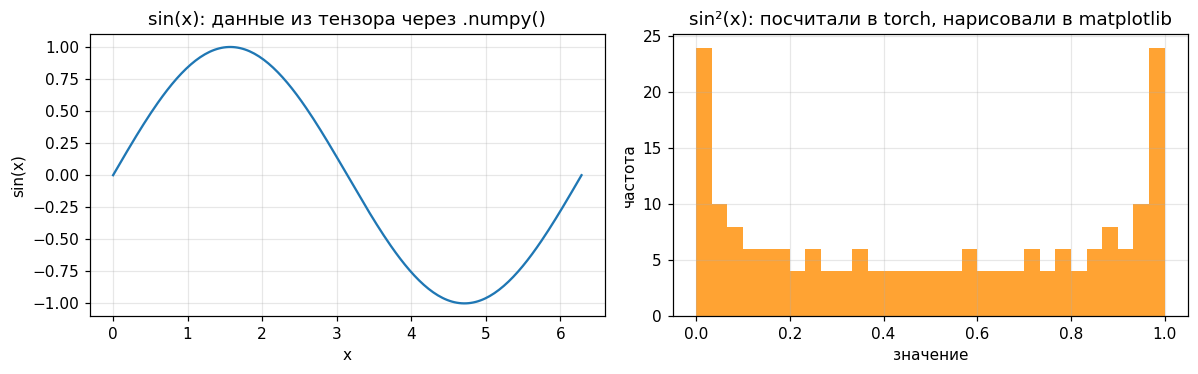

среднее sin²(x) = 0.4975000321865082


In [8]:
# --- практический сценарий: считаем в numpy, рисуем в matplotlib ---
torch_tensor = torch.linspace(0, 2 * np.pi, 200)
y_np = torch_tensor.numpy()              # для matplotlib нужен numpy

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(y_np, np.sin(y_np))
ax[0].set_title('sin(x): данные из тензора через .numpy()')
ax[0].set_xlabel('x'); ax[0].set_ylabel('sin(x)'); ax[0].grid(alpha=0.3)

# обратно: numpy -> тензор, посчитали статистику в torch
x_t = torch.from_numpy(y_np.copy())
ax[1].hist((torch.sin(x_t) ** 2).numpy(), bins=30, alpha=0.8, color='darkorange')
ax[1].set_title('sin²(x): посчитали в torch, нарисовали в matplotlib')
ax[1].set_xlabel('значение'); ax[1].set_ylabel('частота'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('среднее sin²(x) =', (torch.sin(x_t) ** 2).mean().item())

### ✏️ Задание 2

Возьмите массив NumPy `arr0 = np.arange(6).reshape(2, 3)`. Сделайте тензор **без копирования** памяти (`torch.from_numpy`) и тензор **с копией** (`torch.tensor`). Измените `arr0` и проверьте, какой из тензоров отразил изменение.

In [9]:
# ✏️ TODO 2
arr0 =

t_view =    # без копии памяти (view)
t_copy =        # копия

arr0[0, 0] = 100.0

assert t_view is not None and t_copy is not None
assert t_view[0, 0].item() == 100.0, 'view должен отразить изменение arr0'
assert t_copy[0, 0].item() == 0.0, 'copy не должен меняться вместе с arr0'
print('Задание 2 OK ✓ | view видит arr0, copy - независимая копия')

Задание 2 OK ✓ | view видит arr0, copy - независимая копия


### 1.4. Итог по части 1

- Тензор = массив NumPy + `device` + возможность считать градиенты.
- Почти все операции и синтаксис совпадают с NumPy (`@`, `.sum(dim=...)`, broadcasting).
- Метрики и скаляры вытаскиваем через `.item()`.
- Мост к NumPy: `t.numpy()` / `torch.from_numpy(arr)` — **делят память**; `torch.tensor(arr)` — **копирует**.
- С GPU-тензора сначала `.cpu()` (или `.detach().cpu().numpy()`), иначе `.numpy()` упадёт.

---
# Часть 2. Вычисление градиентов над тензорами

В лекции 4 мы выводили `backward` руками для каждого слоя. PyTorch делает это сам: достаточно пометить тензор `requires_grad=True`, и все операции над ним будут **записаны в граф**, а вызов `.backward()` посчитает градиенты по правилу цепочки.

## 2.1. `requires_grad` и граф вычислений

Ключевые понятия:

- `requires_grad=True` — «этот тензор обучаемый, следи за ним»;
- `t.grad` — накопленный градиент (изначально `None`);
- `t.backward()` — обратный проход; считает градиент **только для скалярного** выхода (иначе нужно задать `gradient=`);
- `t.detach()` — «отрезать» тензор от графа (получить значение без истории);
- `torch.no_grad()` — контекст, внутри которого граф **не строится** (нужен на инференсе — экономит память и время).

In [10]:
# --- простейший пример: y = x^2, dy/dx = 2x ---
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2                       # y = 9, граф: x -> x^2
print('x =', x.item(), '  y = x^2 =', y.item())
print('y.requires_grad =', y.requires_grad)

y.backward()                     # обратный проход
print('dy/dx =', x.grad.item(), ' (ожидаем 2*x = 6.0)')
print()
# градиент НАКАПЛИВАЕТСЯ, а не переписывается
y2 = x ** 2
y2.backward()
print('после второго backward: x.grad =', x.grad.item(), ' <-- 6 + 6 = 12 (градиенты сложились!)')
print('поэтому перед новым шагом делают .zero_grad() или x.grad = None')

x = 3.0   y = x^2 = 9.0
y.requires_grad = True
dy/dx = 6.0  (ожидаем 2*x = 6.0)

после второго backward: x.grad = 12.0  <-- 6 + 6 = 12 (градиенты сложились!)
поэтому перед новым шагом делают .zero_grad() или x.grad = None


### Внимание: градиенты накапливаются

Это не случайность, а дизайн: так удобно суммировать градиенты по нескольким батчам (gradient accumulation). Но именно поэтому в цикле обучения **обязательно** обнуляют `.grad` — иначе градиенты с прошлых шагов сложатся с новыми, и обучение «уедет».

Проверим обнуление.

In [11]:
x = torch.tensor(3.0, requires_grad=True)

(x ** 2).backward()
print('шаг 1: grad =', x.grad.item())

# обнуляем перед следующим шагом
x.grad = None                    # или x.grad.zero_()
(x ** 2).backward()
print('шаг 2 после сброса: grad =', x.grad.item(), ' (снова 6, а не 12)')
print()
#.zero_() делает то же самое по значению
x.grad.zero_()
print('после zero_(): grad =', x.grad.item())

шаг 1: grad = 6.0
шаг 2 после сброса: grad = 6.0  (снова 6, а не 12)

после zero_(): grad = 0.0


## 2.2. Граф на нескольких переменных и правило цепочки

Пусть $y = (a + b) \cdot c$, где $a, b, c$ — тензоры. PyTorch сам построит граф `add -> mul` и посчитает все частные производные. Проверим руками, что получится ожидаемое:

$$\frac{\partial y}{\partial a} = c, \qquad \frac{\partial y}{\partial b} = c, \qquad \frac{\partial y}{\partial c} = a + b$$

In [12]:
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(3.0, requires_grad=True)
c = torch.tensor(4.0, requires_grad=True)

s = a + b            # промежуточный узел
y = s * c            # y = (2+3)*4 = 20

y.backward()

print('y =', y.item())
print('dy/da =', a.grad.item(), ' (ожидаем c = 4)')
print('dy/db =', b.grad.item(), ' (ожидаем c = 4)')
print('dy/dc =', c.grad.item(), ' (ожидаем a+b = 5)')

assert a.grad.item() == c.item() == 4.0
assert b.grad.item() == 4.0
assert c.grad.item() == s.item() == 5.0
print('правило цепочки через autograd совпало с ручными формулами ✓')

y = 20.0
dy/da = 4.0  (ожидаем c = 4)
dy/db = 4.0  (ожидаем c = 4)
dy/dc = 5.0  (ожидаем a+b = 5)
правило цепочки через autograd совпало с ручными формулами ✓


## 2.3. Градиент по массиву: линейная регрессия

Теперь содержательный пример. Возьмём данные $y = wx + b$ и функцию потерь MSE:

$$J(w, b) = \frac{1}{n}\sum_{i=1}^{n}(\hat y_i - y_i)^2, \qquad \hat y_i = w x_i + b$$

Аналитически (см. лекцию 2):
$$\frac{\partial J}{\partial w} = \frac{2}{n}\sum_i (\hat y_i - y_i)\,x_i, \qquad \frac{\partial J}{\partial b} = \frac{2}{n}\sum_i (\hat y_i - y_i)$$

Посчитаем градиент через autograd и сверим с формулой.

In [13]:
torch.manual_seed(0)

# данные: y = 3x + 2 + шум
X = torch.linspace(-1, 1, 50).reshape(-1, 1)          # (50, 1)
true_w, true_b = 3.0, 2.0
y_true = true_w * X + true_b + 0.3 * torch.randn(X.shape)

# параметры модели
w = torch.tensor([[0.5]], requires_grad=True)
b = torch.tensor([0.0], requires_grad=True)

# forward
y_pred = X @ w + b
loss = ((y_pred - y_true) ** 2).mean()
print('loss =', loss.item())

# backward: autograd
loss.backward()
print('autograd: dw =', w.grad.item(), '  db =', b.grad.item())

# ручная формула для сверки
n = X.shape[0]
err = (y_pred - y_true)                                # (50, 1)
dw_manual = (2.0 / n) * (err * X).sum()
db_manual = (2.0 / n) * err.sum()
print('вручную : dw =', dw_manual.item(), '  db =', db_manual.item())

assert torch.allclose(w.grad, dw_manual, atol=1e-5)
assert torch.allclose(b.grad, db_manual, atol=1e-5)
print('autograd == аналитическая формула ✓')

loss = 6.4806742668151855
autograd: dw = -1.7943912744522095   db = -4.02929162979126
вручную : dw = -1.7943912744522095   db = -4.029292106628418
autograd == аналитическая формула ✓


### ✏️ Задание 3

Для той же модели посчитайте градиент по `w` и `b` для функции потерь **MAE** (среднее абсолютное отклонение):

$$J = \frac{1}{n}\sum_i |\hat y_i - y_i|$$

Подсказка: производная $|u|$ по $u$ — это $\mathrm{sign}(u)$; в torch это `torch.sign(...)`, а среднее — `.mean()`.

In [14]:
# ✏️ TODO 3
w2 = torch.tensor([[0.5]], requires_grad=True)
b2 = torch.tensor([0.0], requires_grad=True)

y_pred2 =
mae =       # среднее |y_pred - y_true|

err2 =
dw_mae =
db_mae =

assert mae is not None
assert torch.allclose(w2.grad, dw_mae, atol=1e-5)
assert torch.allclose(b2.grad, db_mae, atol=1e-5)
print('Задание 3 OK ✓ | MAE =', mae.item(), '| dW совпал')

Задание 3 OK ✓ | MAE = 2.1225192546844482 | dW совпал


## 2.4. `detach()`, `no_grad()` и почему это важно

- **`t.detach()`** — возвращает тензор с теми же значениями, но **без истории** графа. Нужен, когда значение используется как «константа» (например, метрика или target).
- **`with torch.no_grad():`** — весь блок считается без построения графа. Используется при **валидации и инференсе**: градиенты не нужны, значит незачем тратить память.
- **`.item()`** — тоже «отрезает» значение в Python-число.

Без `no_grad` на инференсе память под граф всё равно тратится, а при большом числе шагов это приводит к переполнению памяти.

In [15]:
x = torch.tensor(2.0, requires_grad=True)
y = x ** 3
print('y.requires_grad          :', y.requires_grad)
print('y.detach().requires_grad :', y.detach().requires_grad)
print('y.item()                 :', y.item(), '(просто число)')
print()
print('with torch.no_grad():')
with torch.no_grad():
    z = x ** 3
    print('  z.requires_grad =', z.requires_grad, ' (граф не строится)')
print()
# практический замер: граф vs без графа по памяти/времени
import time
big = torch.randn(2000, 2000, device=device)

t0 = time.perf_counter()
with torch.no_grad():
    _ = (big @ big).sum().item()
t_nograd = time.perf_counter() - t0

t0 = time.perf_counter()
try:
    _ = (big @ big).sum().item()
    t_grad = time.perf_counter() - t0
except Exception:
    t_grad = float('nan')

print(f'no_grad : {t_nograd*1000:.1f} ms')
print(f'с графом: {t_grad*1000:.1f} ms  (граф стоит памяти и времени)')

y.requires_grad          : True
y.detach().requires_grad : False
y.item()                 : 8.0 (просто число)

with torch.no_grad():
  z.requires_grad = False  (граф не строится)

no_grad : 26.3 ms
с графом: 1.0 ms  (граф стоит памяти и времени)


### 2.5. Итог по части 2

- `requires_grad=True` включает автоматическое дифференцирование; `.backward()` считает градиенты по chain rule.
- `x.grad` **накапливается** → перед каждым шагом обнуляем (`x.grad = None` или `.zero_()`).
- Градиенты можно сверять с аналитическими формулами — это отличный способ проверить, что модель считает правильно (то же, что `check_grad` из лекции 4).
- На инференсе используем `torch.no_grad()`; для «отрезания» значения — `.detach()` или `.item()`.

---
# Часть 3. Модуль `nn`: готовые слои

`torch.nn` — это библиотека готовых слоёв. Каждый слой — потомок `nn.Module` и умеет то же, что наши классы из лекции 4: хранить параметры и считать `forward`. Разница в том, что `backward` PyTorch выводит сам (через autograd), а `nn.Module` ещё и умеет **регистрировать параметры** — то есть автоматически отдавать их оптимизатору и переводить `.to(device)`.

## 3.1. `nn.Linear`

Линейный слой из лекции 4: $Z = XW + b$. В PyTorch:
- `nn.Linear(in_features, out_features)` — слои хранят вес `weight` формы `(out, in)` (транспонирован относительно нашего `W`) и смещение `bias` формы `(out,)`;
- вход — форма `(*, in_features)`, выход — `(*, out_features)`; ведущие размерности (батч) сохраняются.

In [16]:
lin = nn.Linear(3, 2)                 # 3 входа -> 2 выхода
print(lin)
print()
print('weight:', tuple(lin.weight.shape), ' bias:', tuple(lin.bias.shape))
print('weight requires_grad:', lin.weight.requires_grad)

x = torch.randn(5, 3)                 # батч из 5 примеров
out = lin(x)
print()
print('вход :', tuple(x.shape), '-> выход:', tuple(out.shape))
print('проверка вручную (x @ W.T + b):', torch.allclose(out, x @ lin.weight.T + lin.bias))
print()
# перечислим параметры слоя
for name, p in lin.named_parameters():
    print(f'  параметр {name:>6}: shape={tuple(p.shape)}')

Linear(in_features=3, out_features=2, bias=True)

weight: (2, 3)  bias: (2,)
weight requires_grad: True

вход : (5, 3) -> выход: (5, 2)
проверка вручную (x @ W.T + b): True

  параметр weight: shape=(2, 3)
  параметр   bias: shape=(2,)


## 3.2. Функции активации: `ReLU`, `Sigmoid`, `Softmax`

Это те же функции, что в лекции 4, но теперь как готовые модули (`nn.ReLU`) или функции (`F.relu`). Обратите внимание:

- `nn.ReLU()` — **объект-слой** (без параметров), применяется как `relu(x)`;
- `F.relu(x)` — **функция**, вызывается сразу;
- `nn.Softmax(dim=-1)` — обязательно указывать ось: softmax нужен вдоль классов (последняя ось);
- `nn.Sigmoid()` — сжимает в `(0, 1)` поэлементно.

Сравним все на одном входе.

In [17]:
z = torch.tensor([[-2.0, -0.5, 0.0, 1.0, 3.0]])

relu_layer = nn.ReLU()
print('вход      z =', z.tolist()[0])
print('ReLU      =', relu_layer(z).tolist()[0])
print('Sigmoid   =', [round(v, 4) for v in nn.Sigmoid()(z).tolist()[0]])
print()
# softmax вдоль классов
logits = torch.tensor([[2.0, 1.0, 0.5, -1.0]])
sm = nn.Softmax(dim=-1)
probs = sm(logits)
print('logits      =', logits.tolist()[0])
print('softmax     =', [round(v, 4) for v in probs.tolist()[0]])
print('сумма       =', probs.sum().item(), '(всегда 1)')
print()
# один и тот же результат через объект и через функцию
print('nn.ReLU(z) == F.relu(z):', torch.allclose(nn.ReLU()(z), F.relu(z)))
print('nn.Softmax(dim=-1)(logits) == F.softmax(logits, dim=-1):',
      torch.allclose(nn.Softmax(dim=-1)(logits), F.softmax(logits, dim=-1)))

вход      z = [-2.0, -0.5, 0.0, 1.0, 3.0]
ReLU      = [0.0, 0.0, 0.0, 1.0, 3.0]
Sigmoid   = [0.1192, 0.3775, 0.5, 0.7311, 0.9526]

logits      = [2.0, 1.0, 0.5, -1.0]
softmax     = [0.6095, 0.2242, 0.136, 0.0303]
сумма       = 1.0 (всегда 1)

nn.ReLU(z) == F.relu(z): True
nn.Softmax(dim=-1)(logits) == F.softmax(logits, dim=-1): True


### Визуализация активаций

Посмотрим формы функций и их производные — ровно те, что мы разбирали в лекции 4 (влияние на градиенты).

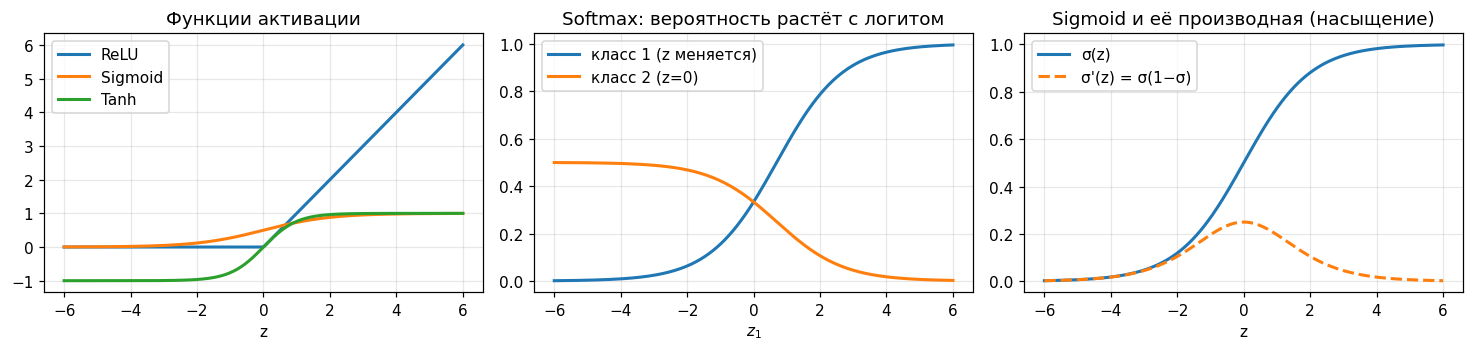

In [18]:
xs = torch.linspace(-6, 6, 300)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.3))

axes[0].plot(xs.numpy(), torch.relu(xs).numpy(), lw=2, label='ReLU')
axes[0].plot(xs.numpy(), torch.sigmoid(xs).numpy(), lw=2, label='Sigmoid')
axes[0].plot(xs.numpy(), torch.tanh(xs).numpy(), lw=2, label='Tanh')
axes[0].set_title('Функции активации'); axes[0].set_xlabel('z'); axes[0].legend(); axes[0].grid(alpha=0.3)

# softmax на трёх логитах: как меняются вероятности при сдвиге одного логита
z0 = torch.linspace(-6, 6, 200)
soft = torch.stack([F.softmax(torch.stack([z0[i], torch.tensor(0.0), torch.tensor(0.0)]), dim=0)
                    for i in range(len(z0))])
axes[1].plot(z0.numpy(), soft[:, 0].numpy(), lw=2, label='класс 1 (z меняется)')
axes[1].plot(z0.numpy(), soft[:, 1].numpy(), lw=2, label='класс 2 (z=0)')
axes[1].set_title('Softmax: вероятность растёт с логитом'); axes[1].set_xlabel('$z_1$'); axes[1].legend(); axes[1].grid(alpha=0.3)

# производные
g = torch.linspace(-6, 6, 300, requires_grad=True)
sig = torch.sigmoid(g).sum()
sig.backward()
axes[2].plot(g.detach().numpy(), torch.sigmoid(g).detach().numpy(), lw=2, label='σ(z)')
axes[2].plot(g.detach().numpy(), g.grad.numpy(), '--', lw=2, label="σ'(z) = σ(1−σ)")
axes[2].set_title('Sigmoid и её производная (насыщение)'); axes[2].set_xlabel('z')
axes[2].legend(); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3.3. Функции потерь: `MSELoss`, `CrossEntropyLoss`, `NLLLoss`

Три функции, которые понадобятся чаще всего:

1. **`nn.MSELoss()`** — регрессия: $\frac{1}{n}\sum(\hat y - y)^2$. Вход — предсказания и цели одной формы.
2. **`nn.NLLLoss()`** — «negative log-likelihood»: принимает **логарифмы вероятностей** (`log_softmax`) и целочисленные метки.
3. **`nn.CrossEntropyLoss()`** — то же, что `LogSoftmax + NLLLoss` **в одном вызове**. Принимает «сырые» логиты и метки классов (класс берётся по индексу — не one-hot!).

Именно `CrossEntropyLoss` — стандартный выбор для классификации. Проверим численно, что он совпадает с `NLLLoss(log_softmax(...))` — это та самая «слитая» функция из лекции 4 (§1.7.1).

In [19]:
# --- MSELoss ---
pred = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
target = torch.tensor([[1.5, 2.5], [2.5, 4.5]])
mse = nn.MSELoss()
print('MSE =', mse(pred, target).item(), ' (руками:', ((pred - target) ** 2).mean().item(), ')')
print()

# --- CrossEntropyLoss: логиты (n, K) + метки (n,) ---
logits = torch.tensor([[2.0, 1.0, 0.5],
                       [0.1, 2.5, 0.2]])
labels = torch.tensor([0, 1])          # целые метки классов
ce = nn.CrossEntropyLoss()
loss_ce = ce(logits, labels)
print('CrossEntropyLoss          =', loss_ce.item())

# эквивалент: log_softmax + NLLLoss
log_probs = F.log_softmax(logits, dim=1)
nll = nn.NLLLoss()
loss_nll = nll(log_probs, labels)
print('NLLLoss(log_softmax(logits)) =', loss_nll.item())
print('совпадают:', torch.allclose(loss_ce, loss_nll))
print()

# убедимся, что CE "сливает" softmax+log: смотрим на распределение вероятностей
probs = F.softmax(logits, dim=1)
print('вероятности:', [[round(v, 3) for v in row] for row in probs.tolist()])
print('NLL = -mean(log p[правильный класс]) =',
      (-torch.log(probs[torch.arange(2), labels])).mean().item())

MSE = 0.25  (руками: 0.25 )

CrossEntropyLoss          = 0.31957125663757324
NLLLoss(log_softmax(logits)) = 0.31957125663757324
совпадают: True

вероятности: [[0.629, 0.231, 0.14], [0.076, 0.84, 0.084]]
NLL = -mean(log p[правильный класс]) = 0.319571316242218


### Важный нюанс: `CrossEntropyLoss` не принимает one-hot

Если метки заданы one-hot (например `[0, 1, 0]`), их нужно перевести в индексы через `argmax`. Это одна из самых частых ошибок. Покажем обе ситуации.

In [20]:
# one-hot метки -> индексы
onehot = torch.tensor([[1.0, 0.0, 0.0],
                       [0.0, 1.0, 0.0]])
idx = onehot.argmax(dim=1)
print('one-hot:', onehot.tolist())
print('индексы:', idx.tolist())
print('loss с индексами:', nn.CrossEntropyLoss()(logits, idx).item())
print()
# если передать one-hot напрямую - ошибка формы
try:
    nn.CrossEntropyLoss()(logits, onehot)
except Exception as e:
    print('передача one-hot напрямую падает:', type(e).__name__)
    print(str(e).splitlines()[0])

one-hot: [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]
индексы: [0, 1]
loss с индексами: 0.31957125663757324



## 3.4. `nn.Sequential`: собираем сеть из слоёв

`nn.Sequential` — контейнер, который прогоняет вход **последовательно** через слои. Это прямой аналог нашего `Sequential` из лекции 4.

$$x \longrightarrow \text{Linear}(2\to 8) \longrightarrow \text{ReLU} \longrightarrow \text{Linear}(8\to 2) \longrightarrow \text{logits}$$

In [21]:
net = nn.Sequential(
    nn.Linear(2, 8),
    nn.ReLU(),
    nn.Linear(8, 2),
)
print(net)
print()
x = torch.randn(4, 2)
out = net(x)
print('вход:', tuple(x.shape), '-> выход (логиты):', tuple(out.shape))
print()
# параметры всей сети разом
total = sum(p.numel() for p in net.parameters())
print('всего параметров:', total, ' (2*8+8 + 8*2+2 = 24 + 18 = 42)')
for name, p in net.named_parameters():
    print(f'  {name:>14}: {tuple(p.shape)}')

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=2, bias=True)
)

вход: (4, 2) -> выход (логиты): (4, 2)

всего параметров: 42  (2*8+8 + 8*2+2 = 24 + 18 = 42)
        0.weight: (8, 2)
          0.bias: (8,)
        2.weight: (2, 8)
          2.bias: (2,)


### Доступ к слоям и `nn.ModuleList`

Иногда нужен доступ к отдельным слоям (например, чтобы задать инициализацию или заморозить часть). У `Sequential` слои лежат по индексу: `net[0]`, `net[2]`.

Если слоёв много и их число задаётся переменной, используют **`nn.ModuleList`** — список модулей, который правильно регистрирует их параметры. Обычный Python-список `[]` этого **не делает**, и параметры «потеряются» для оптимизатора. Покажем разницу.

In [22]:
# доступ к слоям по индексу
print('net[0]:', net[0])
print('net[2]:', net[2])
print()

# --- ModuleList vs обычный list ---
class NetList(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(4, 4) for _ in range(3)])   # правильно

    def forward(self, x):
        for layer in self.layers:
            x = F.relu(layer(x))
        return x

class NetPlain(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(4, 4) for _ in range(3)]                  # ОШИБКА: не регистрируется

    def forward(self, x):
        for layer in self.layers:
            x = F.relu(layer(x))
        return x

n_modulelist = NetList()
n_plain = NetPlain()
print('ModuleList  : параметров видно оптимизатору =', sum(p.numel() for p in n_modulelist.parameters()))
print('plain list  : параметров видно оптимизатору =', sum(p.numel() for p in n_plain.parameters()), ' (0! параметры потеряны)')
print()
print('вывод: слои, которые должны обучаться, храните в nn.ModuleList (или nn.Sequential), а не в обычном списке')

net[0]: Linear(in_features=2, out_features=8, bias=True)
net[2]: Linear(in_features=8, out_features=2, bias=True)

ModuleList  : параметров видно оптимизатору = 60
plain list  : параметров видно оптимизатору = 0  (0! параметры потеряны)

вывод: слои, которые должны обучаться, храните в nn.ModuleList (или nn.Sequential), а не в обычном списке


### Свой `nn.Module`

Собрать собственную сеть можно и без `Sequential` — унаследовавшись от `nn.Module` и описав `forward`. Это тот же контракт, что в лекции 4: в `__init__` объявляем слои, в `forward` — как они соединены.

In [23]:
class MLP(nn.Module):
    def __init__(self, n_in, n_hidden, n_out):
        super().__init__()                     # обязательно
        self.fc1 = nn.Linear(n_in, n_hidden)
        self.fc2 = nn.Linear(n_hidden, n_hidden)
        self.fc3 = nn.Linear(n_hidden, n_out)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)                     # логиты

model = MLP(2, 16, 2)
out = model(torch.randn(5, 2))
print(model)
print()
print('выход:', tuple(out.shape))
print('параметров:', sum(p.numel() for p in model.parameters()))

MLP(
  (fc1): Linear(in_features=2, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=2, bias=True)
)

выход: (5, 2)
параметров: 354


### ✏️ Задание 4

Соберите `nn.Sequential`, который делает: `Linear(4 → 6)` → `ReLU` → `Linear(6 → 3)` → `Softmax(dim=-1)`. Прогоните через него батч из 5 примеров и проверьте, что выход имеет форму `(5, 3)` и каждая строка суммируется в 1.

In [24]:
# ✏️ TODO 4
model4 =

assert model4 is not None, 'соберите сеть'
assert isinstance(model4, nn.Sequential)
out4 = model4(torch.randn(5, 4))
assert tuple(out4.shape) == (5, 3), f'ожидали (5,3), получили {tuple(out4.shape)}'
assert torch.allclose(out4.sum(dim=1), torch.ones(5), atol=1e-5), 'строки должны суммироваться в 1'
print('Задание 4 OK ✓ | форма', tuple(out4.shape), '| суммы строк:', out4.sum(dim=1).tolist())

Задание 4 OK ✓ | форма (5, 3) | суммы строк: [1.0, 1.0000001192092896, 1.0, 1.0, 1.0]


### 3.5. Итог по части 3

- `nn.Linear(in, out)` — линейный слой; вес хранится как `(out, in)`.
- `nn.ReLU`, `nn.Sigmoid`, `nn.Softmax(dim=-1)` — активации; то же доступно как функции `F.*`.
- `nn.MSELoss` — регрессия; `nn.CrossEntropyLoss` = `LogSoftmax` + `NLLLoss` и ждёт **целые** метки.
- `nn.Sequential` — последовательная сеть; `nn.ModuleList` — правильное хранение списка слоёв; свой `nn.Module` — полный контроль.

---
# Часть 4. Модуль `nn.functional` и инициализация весов

## 4.1. `nn.functional` vs `nn.Module`

В PyTorch многое доступно в **двух** видах:

| Что это | Как слой (Module) | Как функция (`F.`) |
|---|---|---|
| ReLU | `nn.ReLU()` | `F.relu(x)` |
| Sigmoid | `nn.Sigmoid()` | `torch.sigmoid(x)` |
| Softmax | `nn.Softmax(dim=-1)` | `F.softmax(x, dim=-1)` |
| CrossEntropy | `nn.CrossEntropyLoss()` | `F.cross_entropy(logits, y)` |
| Dropout | `nn.Dropout(p)` | `F.dropout(x, p, training=...)` |

Правило простое: если у операции **есть обучаемые параметры** или **состояние** (как у `Dropout`, `BatchNorm`), нужен модуль. Если это чистая функция от входа (ReLU, softmax, loss) — можно взять `F.*`. В `forward` собственной сети чаще пишут `F.*` — короче.

In [25]:
x = torch.tensor([[-1.0, 0.0, 2.0]])
logits = torch.tensor([[1.0, 2.0, 3.0]])
y = torch.tensor([2])

# Module-объект vs функциональная форма - результат один и тот же
print('nn.ReLU()(x)      =', nn.ReLU()(x).tolist()[0], '| F.relu(x)      =', F.relu(x).tolist()[0])
print('nn.Softmax()(logits) =', [round(v, 4) for v in nn.Softmax(dim=-1)(logits).tolist()[0]])
print('F.softmax(logits)    =', [round(v, 4) for v in F.softmax(logits, dim=-1).tolist()[0]])
print('nn.CrossEntropyLoss() =', nn.CrossEntropyLoss()(logits, y).item(),
      '| F.cross_entropy =', F.cross_entropy(logits, y).item())
print()
# полезные функции F. на каждый день
a = torch.randn(2, 5)
print('F.one_hot([0,2], 4) :\n', F.one_hot(torch.tensor([0, 2]), num_classes=4))
print()
print('F.normalize(a, dim=1): нормы строк =', F.normalize(a, dim=1).norm(dim=1).tolist(), '(все 1)')

nn.ReLU()(x)      = [0.0, 0.0, 2.0] | F.relu(x)      = [0.0, 0.0, 2.0]
nn.Softmax()(logits) = [0.09, 0.2447, 0.6652]
F.softmax(logits)    = [0.09, 0.2447, 0.6652]
nn.CrossEntropyLoss() = 0.40760594606399536 | F.cross_entropy = 0.40760594606399536

F.one_hot([0,2], 4) :
 tensor([[1, 0, 0, 0],
        [0, 0, 1, 0]])

F.normalize(a, dim=1): нормы строк = [0.9999999403953552, 1.0] (все 1)


### `Dropout`: почему он требует флага `training`

`Dropout` случайно обнуляет часть нейронов при обучении и **выключается** на инференсе. Это состояние, поэтому ему нужен флаг: у модуля `nn.Dropout` есть `.train()/.eval()`, а у функции `F.dropout` — явный аргумент `training=True/False`.

Важно: вызов `model.train()` / `model.eval()` **переключает этот флаг у всех вложенных модулей** разом.

In [26]:
torch.manual_seed(0)
x = torch.ones(1, 10)

print('F.dropout(training=True) :', F.dropout(x, p=0.5, training=True).tolist()[0], ' <-- часть нулей, остальные масштабированы')
print('F.dropout(training=False):', F.dropout(x, p=0.5, training=False).tolist()[0], ' <-- без изменений')
print()

# у модуля флаг переключается .train()/.eval()
class NetDropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(10, 10)
        self.drop = nn.Dropout(0.5)

    def forward(self, x):
        return self.drop(self.fc(x))

nd = NetDropout()
nd.train()
print('nd.training (после .train()):', nd.training)
o1 = nd(torch.ones(1, 10))
nd.eval()
print('nd.training (после .eval()):', nd.training)
o2 = nd(torch.ones(1, 10))
print('в train часть выходов нулевая:', (o1 == 0).any().item())
print('в eval выход детерминированный   :', torch.allclose(o2, nd.fc(torch.ones(1, 10))))

F.dropout(training=True) : [2.0, 0.0, 0.0, 2.0, 2.0, 0.0, 0.0, 2.0, 2.0, 2.0]  <-- часть нулей, остальные масштабированы
F.dropout(training=False): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]  <-- без изменений

nd.training (после .train()): True
nd.training (после .eval()): False
в train часть выходов нулевая: True
в eval выход детерминированный   : True


## 4.2. Инициализация весов

Из лекции 4 (§4) мы знаем:

- **нулями** (и любой одинаковой инициализацией) нельзя — все нейроны слоя останутся клонами;
- масштаб должен сохранять дисперсию сигнала: **Xavier** ($\mathrm{Var}(w)\approx 1/d_{in}$) для `tanh`/`sigmoid`, **He** ($2/d_{in}$) для `ReLU`.

PyTorch **сам** инициализирует `nn.Linear` по схеме Kaiming-uniform (это вариант He). Но инициализацию можно задать вручную через `nn.init.*`:

| Функция | Что делает |
|---|---|
| `nn.init.zeros_(t)` / `ones_` | заполняет константой |
| `nn.init.normal_(t, 0, std)` | нормальное распределение |
| `nn.init.xavier_uniform_` / `xavier_normal_` | Xavier (Glorot) |
| `nn.init.kaiming_uniform_` / `kaiming_normal_` | He (Kaiming) |

Суффикс `_` означает «меняет тензор на месте» (in-place).

In [27]:
# экспериментальная функция: посмотреть std весов после разной инициализации
def init_layer(layer, kind):
    if kind == 'zeros':
        nn.init.zeros_(layer.weight)
    elif kind == 'normal_small':
        nn.init.normal_(layer.weight, mean=0.0, std=0.01)
    elif kind == 'xavier':
        nn.init.xavier_uniform_(layer.weight)
    elif kind == 'kaiming':
        nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
    nn.init.zeros_(layer.bias)

tests = ['zeros', 'normal_small', 'xavier', 'kaiming']
print(f'{"инициализация":>14} | {"std(W)":>8} | {"min":>8} | {"max":>8}')
print('-' * 48)
for kind in tests:
    lin = nn.Linear(64, 64)
    init_layer(lin, kind)
    w = lin.weight.detach()
    print(f'{kind:>14} | {w.std().item():>8.4f} | {w.min().item():>8.4f} | {w.max().item():>8.4f}')
print()
print('теоретический ориентир:')
print('  Xavier: Var ~ 1/fan_in     -> std ~', round((1 / 64) ** 0.5, 4))
print('  He    : Var ~ 2/fan_in     -> std ~', round((2 / 64) ** 0.5, 4))

 инициализация |   std(W) |      min |      max
------------------------------------------------
         zeros |   0.0000 |   0.0000 |   0.0000
  normal_small |   0.0101 |  -0.0434 |   0.0342
        xavier |   0.1240 |  -0.2162 |   0.2165
       kaiming |   0.1761 |  -0.5571 |   0.6040

теоретический ориентир:
  Xavier: Var ~ 1/fan_in     -> std ~ 0.125
  He    : Var ~ 2/fan_in     -> std ~ 0.1768


### Как инициализация влияет на прохождение сигнала

Проведём тот же эксперимент, что в лекции 4 (§4.2): прогоним сигнал через 8 линейных слоёв при разном масштабе весов и посмотрим, как меняется `std` активаций по глубине. При слишком маленьком масштабе сигнал гаснет, при слишком большом — взрывается; правильный — сохраняет масштаб.

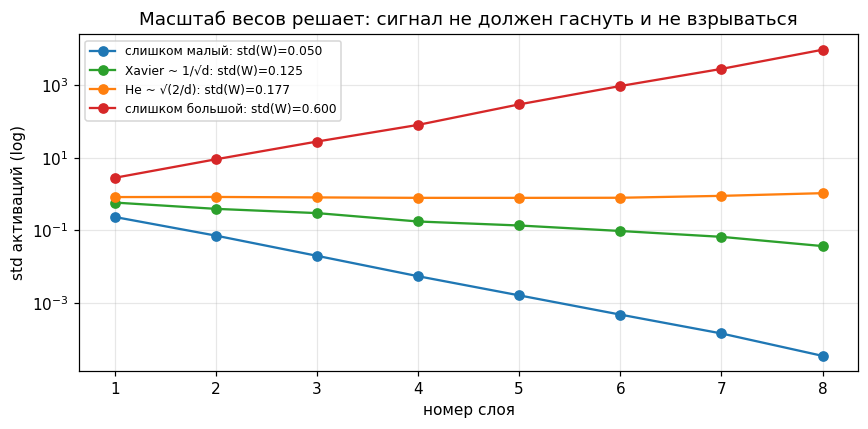

In [28]:
torch.manual_seed(0)
depths = range(1, 9)
scales = {'слишком малый': 0.05, 'Xavier ~ 1/√d': None, 'He ~ √(2/d)': None, 'слишком большой': 0.6}
fan_in = 64
resolved = {
    'слишком малый': 0.05,
    'Xavier ~ 1/√d': (1.0 / fan_in) ** 0.5,
    'He ~ √(2/d)': (2.0 / fan_in) ** 0.5,
    'слишком большой': 0.6,
}
colors = ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']

fig, ax = plt.subplots(figsize=(8, 4))
for (label, sc), col in zip(resolved.items(), colors):
    x = torch.randn(256, fan_in)
    stds = []
    for _ in depths:
        W = torch.randn(fan_in, fan_in) * sc
        x = torch.relu(x @ W)
        stds.append(x.std().item())
    ax.plot(list(depths), stds, 'o-', color=col, label=f'{label}: std(W)={sc:.3f}')
ax.set_yscale('log')
ax.set_xlabel('номер слоя'); ax.set_ylabel('std активаций (log)')
ax.set_title('Масштаб весов решает: сигнал не должен гаснуть и не взрываться')
ax.legend(fontsize=8); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

### Инициализация целой сети

Удобный паттерн — пройтись по всем модулям сети и применить `nn.init` там, где нужно. `model.apply(fn)` вызывает `fn` для каждого модуля (и вложенного тоже).

In [29]:
def init_weights(m):
    '''Применяется к каждому модулю сети: Linear -> Kaiming, bias -> 0.'''
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
        nn.init.zeros_(m.bias)

net4 = nn.Sequential(nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, 4))

# сначала занулим, чтобы было видно эффект
for m in net4.modules():
    if isinstance(m, nn.Linear):
        nn.init.zeros_(m.weight)
print('после zeros_: std W1 =', net4[0].weight.std().item())

net4.apply(init_weights)     # применяем нашу инициализацию ко всем слоям
print('после apply(init_weights):')
for name, p in net4.named_parameters():
    print(f'  {name:>12}: std={p.std().item():.4f}  mean={p.mean().item():+.4f}')

после zeros_: std W1 = 0.0
после apply(init_weights):
      0.weight: std=0.5227  mean=-0.0483
        0.bias: std=0.0000  mean=+0.0000
      2.weight: std=0.3197  mean=-0.1042
        2.bias: std=0.0000  mean=+0.0000


### ✏️ Задание 5

Создайте `nn.Linear(32, 32)`, инициализируйте вес **Xavier normal** (`nn.init.xavier_normal_`), а смещение — нулями. Проверьте, что `std(W)` близко к теоретическому $\sqrt{2/(fan_{in}+fan_{out})}$ (для Xavier normal это именно так), скажем, в пределах 25%.

In [30]:
# ✏️ TODO 5
lin5 =

w5 = lin5.weight.detach()
theoretical = (2.0 / (32 + 32)) ** 0.5
assert lin5.bias.abs().sum().item() == 0.0, 'bias должен быть нулём'
assert abs(w5.std().item() - theoretical) / theoretical < 0.25, \
    f'std(W)={w5.std().item():.4f} далеко от теоретического {theoretical:.4f}'
print(f'Задание 5 OK ✓ | std(W)={w5.std().item():.4f}, теория={theoretical:.4f}')

Задание 5 OK ✓ | std(W)=0.1720, теория=0.1768


### 4.3. Итог по части 4

- `nn.functional` (`F.*`) — функциональная форма тех же операций; для операций без состояния это удобнее.
- `Dropout` (и `BatchNorm`) требуют флага режима: `model.train()` / `model.eval()` переключают его у всех подмодулей.
- PyTorch инициализирует слои сам (Kaiming), но можно задать вручную через `nn.init.*`.
- Правильный масштаб инициализации сохраняет дисперсию по глубине; `model.apply(fn)` — способ применить инициализацию ко всей сети.

---
# Часть 5. Обновление весов: SGD вручную

Прежде чем звать готовый оптимизатор, сделаем шаг градиентного спуска **руками**. Формула стохастического градиентного спуска (SGD):

$$\theta \leftarrow \theta - \eta \cdot \nabla_\theta J$$

где $\eta$ — learning rate, а $\nabla_\theta J$ берётся по текущему мини-батчу.

Ключевой технический момент: с тензорами, у которых `requires_grad=True`, **нельзя** менять значение обычной операцией `w = w - lr * w.grad`, потому что вы создадите новый тензор внутри графа. Изменение параметра делают **на месте** и **без графа** — внутри `with torch.no_grad():`.

In [31]:
torch.manual_seed(0)

# линейная регрессия: y = 2x - 1
X = torch.linspace(-2, 2, 100).reshape(-1, 1)
y_true = 2.0 * X - 1.0 + 0.2 * torch.randn(X.shape[0], 1)

w = torch.zeros(1, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

lr = 0.1
losses = []

for step in range(100):
    # 1) forward
    y_pred = X @ w + b
    loss = ((y_pred - y_true) ** 2).mean()

    # 2) backward
    loss.backward()

    # 3) обновление параметров - ВНУТРИ no_grad и НА МЕСТЕ (in-place)
    with torch.no_grad():
        w -= lr * w.grad           # in-place: w.sub_(lr * w.grad)
        b -= lr * b.grad

    # 4) обнуляем градиенты
    w.grad = None
    b.grad = None

    losses.append(loss.item())

print(f'выучили  w = {w.item():.3f}  b = {b.item():.3f}   (истина: 2.0 и -1.0)')
print(f'loss: {losses[0]:.3f} -> {losses[-1]:.4f}')

выучили  w = 2.000  b = -0.993   (истина: 2.0 и -1.0)
loss: 6.468 -> 0.0420


### Что произойдёт без `no_grad` и без обнуления градиентов

Две самые частые ошибки новичка. Покажем их эффект:

1. **in-place** обновление параметра **вне** `no_grad` — `RuntimeError` (а присваивание `w = w - lr*grad` создаёт новый тензор и «отвязывает» имя от параметра модели);
2. отсутствие обнуления `.grad` — градиенты **накапливаются**, и эффективный learning rate «едет».

In [32]:
# Ошибка 1: как НЕ надо обновлять параметры
w = torch.zeros(1, requires_grad=True)
(w * 2).sum().backward()
print('w.grad =', w.grad.item())

# (a) in-place обновление leaf-тензора ВНЕ no_grad -> RuntimeError
try:
    w.sub_(0.1 * w.grad)
except RuntimeError as e:
    print('(a) in-place без no_grad -> RuntimeError:', str(e).splitlines()[0])

# (b) присваивание w = w - lr*grad создаёт НОВЫЙ тензор и "отвязывает" имя
#     от исходного (если параметр зарегистрирован в модели/оптимизаторе - он не обновится)
w_new = w - 0.1 * w.grad
print('(b) w - lr*grad создаёт новый тензор: is leaf =', w_new.is_leaf,
      '| требует grad =', w_new.requires_grad)

# (c) ПРАВИЛЬНО: обновляем на месте и внутри no_grad
with torch.no_grad():
    w.sub_(0.1 * w.grad)      # теперь без ошибки
w.grad = None
print("(c) в no_grad in-place работает: w =", w.item(), '| grad сброшен ->', w.grad)

w.grad = 2.0
(a) in-place без no_grad -> RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.
(b) w - lr*grad создаёт новый тензор: is leaf = False | требует grad = True
(c) в no_grad in-place работает: w = -0.20000000298023224 | grad сброшен -> None


In [33]:
# Ошибка 2: не обнуляем градиенты -> они накапливаются
torch.manual_seed(0)
X = torch.linspace(-2, 2, 100).reshape(-1, 1)
y_true = 2.0 * X - 1.0

def train(lr, zero_grad, steps=30):
    w = torch.zeros(1, 1, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    for _ in range(steps):
        loss = ((X @ w + b - y_true) ** 2).mean()
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        if zero_grad:                        # правильное обнуление
            w.grad = None
            b.grad = None
    return loss.item(), w.item()

l_ok, w_ok = train(0.1, zero_grad=True)
l_bad, w_bad = train(0.1, zero_grad=False)
print(f'с обнулением   : loss={l_ok:.4f}  w={w_ok:+.3f}')
print(f'без обнуления  : loss={l_bad:.4f}  w={w_bad:+.3f}   (градиенты накопились -> шаг огромный)')

с обнулением   : loss=0.0000  w=+2.000
без обнуления  : loss=6.2978  w=+3.919   (градиенты накопились -> шаг огромный)


### Кривая обучения

Визуализируем, как падает loss по шагам. Именно эту картинку мы будем строить на MNIST.

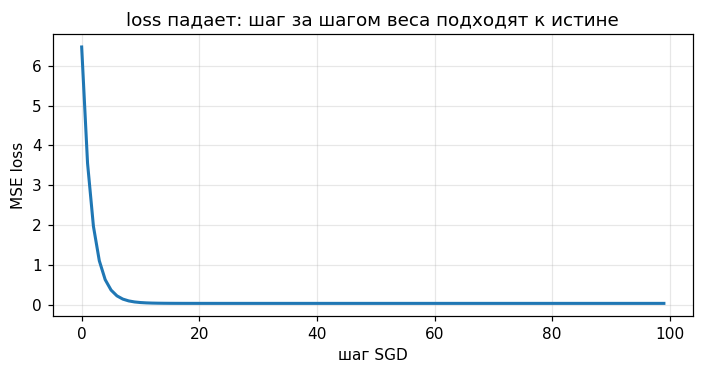

первые 5 значений loss: [6.4675, 3.5554, 1.9732, 1.1098, 0.6362]
последние 5 значений  : [0.042, 0.042, 0.042, 0.042, 0.042]


In [34]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(losses, lw=2)
ax.set_xlabel('шаг SGD'); ax.set_ylabel('MSE loss')
ax.set_title('loss падает: шаг за шагом веса подходят к истине')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('первые 5 значений loss:', [round(v, 4) for v in losses[:5]])
print('последние 5 значений  :', [round(v, 4) for v in losses[-5:]])

### ✏️ Задание 6

Реализуйте функцию `sgd_step(params, lr)`, которая делает один шаг SGD **по списку параметров** (обобщение шага выше). Она нужна будет в следующем пункте, где мы повторим цикл без «ручных» `w -= ...`.

In [35]:
# ✏️ TODO 6
def sgd_step(params, lr):
    '''params: список тензоров с requires_grad=True и заполненным .grad.'''


# проверка на простой задаче
torch.manual_seed(0)
X = torch.linspace(-2, 2, 100).reshape(-1, 1)
y_true = 2.0 * X - 1.0
w = torch.zeros(1, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
for _ in range(200):
    loss = ((X @ w + b - y_true) ** 2).mean()
    loss.backward()
    sgd_step([w, b], lr=0.1)

assert abs(w.item() - 2.0) < 0.05 and abs(b.item() + 1.0) < 0.05, (w.item(), b.item())
print(f'Задание 6 OK ✓ | sgd_step выучил w={w.item():.3f}, b={b.item():.3f}')

Задание 6 OK ✓ | sgd_step выучил w=2.000, b=-1.000


### 5.1. Итог по части 5

- Шаг SGD = `forward` → `loss.backward()` → обновление параметров → обнуление `.grad`.
- Обновлять параметры нужно **на месте** и **внутри `with torch.no_grad():`**.
- Обнуление `.grad` обязательно, иначе градиенты накапливаются с прошлых шагов.
- Скорость обучения `lr` — главный гиперпараметр: слишком большой шаг расходится, слишком маленький — ползёт.

---
# Часть 6. `Dataset` и `DataLoader`

До сих пор мы обучались на **всей** матрице `X` сразу (full-batch). Для больших данных так нельзя: батч нужен, чтобы помещаться в память и делать много обновлений (см. лекцию 4, часть 3). За это в PyTorch отвечают:

- **`Dataset`** — знает, *сколько* у нас примеров (`__len__`) и *как достать один* пример по индексу (`__getitem__(i)`);
- **`DataLoader`** — обёртка над `Dataset`: собирает примеры в батчи, перемешивает, может грузить параллельно (`num_workers`) и готовить данные для GPU (`pin_memory`).

$$\text{Dataset}\;\xrightarrow{\;\text{DataLoader}\;}\;\text{батчи}\;\xrightarrow{\;\text{цикл}\;}\;\text{обновления $\theta$}$$

## 6.1. Свой `Dataset`: `TensorDataset` и класс

Простейший случай — когда данные уже лежат в тензорах. Тогда `TensorDataset` сделает всё сам. Но чаще нужен **свой** `Dataset`, потому что данные большие или требуют преобразований. Рассмотрим оба.

In [36]:
# --- вариант 1: TensorDataset (данные уже в тензорах) ---
X_all = torch.randn(100, 3)
y_all = (X_all.sum(dim=1) > 0).long()

ds_tensor = torch.utils.data.TensorDataset(X_all, y_all)
print('TensorDataset: len =', len(ds_tensor))
x0, y0 = ds_tensor[0]
print('один пример: x =', tuple(x0.shape), ' y =', y0.item())
print()

# --- вариант 2: свой Dataset ---
class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)              # сколько примеров

    def __getitem__(self, i):
        return self.X[i], self.y[i]     # один пример (x_i, y_i)

ds_custom = MyDataset(X_all, y_all)
print('MyDataset: len =', len(ds_custom))
x0, y0 = ds_custom[5]
print('пример #5: x =', x0.tolist(), ' y =', y0.item())

TensorDataset: len = 100
один пример: x = (3,)  y = 0

MyDataset: len = 100
пример #5: x = [-0.2472781538963318, -1.3526537418365479, -1.6959311962127686]  y = 0


### `DataLoader`: батчи, перемешивание, параллельная загрузка

Главный параметр — `batch_size`. Также важны:

- `shuffle=True` — перемешивать порядок каждый эпоху (обязательно для обучения, чтобы батчи были не «сортированными»);
- `num_workers` — сколько процессов грузят данные параллельно (0 значит «в главном процессе»);
- `pin_memory=True` — заранее класть батч в «pinned» память, чтобы быстрее копировать на GPU;
- `drop_last=True` — выбросить неполный последний батч (полезно, если нужны одинаковые размеры, например для BatchNorm).

Важно: `num_workers > 0` плохо сочетается с данными, которые уже лежат на GPU, поэтому данные держат на CPU, а батч переносят на `device` в цикле (как в лекции 4).

In [37]:
loader = DataLoader(ds_custom, batch_size=16, shuffle=True, num_workers=0)
print('батчей в эпоху:', len(loader), '(100 примеров / 16 = 7 батчей)')

xb, yb = next(iter(loader))
print('первый батч: X =', tuple(xb.shape), ' y =', tuple(yb.shape))
print()

# посмотрим, как меняются размеры батчей, если не задавать drop_last
loader_dl = DataLoader(ds_custom, batch_size=32, shuffle=False, drop_last=True)
sizes = [tuple(xb.shape)[0] for xb, _ in loader_dl]
print('batch_size=32, drop_last=True : размеры батчей =', sizes)
loader_full = DataLoader(ds_custom, batch_size=32, shuffle=False)
sizes2 = [tuple(xb.shape)[0] for xb, _ in loader_full]
print('batch_size=32, drop_last=False: размеры батчей =', sizes2, '(последний неполный)')

батчей в эпоху: 7 (100 примеров / 16 = 7 батчей)
первый батч: X = (16, 3)  y = (16,)

batch_size=32, drop_last=True : размеры батчей = [32, 32, 32]
batch_size=32, drop_last=False: размеры батчей = [32, 32, 32, 4] (последний неполный)


### Зачем `shuffle`

Если данные упорядочены (например, все классы 0 идут сначала, потом все классы 1), обучение без перемешивания даст батчи из одного класса — градиент будет «косым», и сеть будет учиться плохо. Покажем это наглядно.

In [38]:
# специально упорядоченные данные: сначала все 0, потом все 1
X_sorted = torch.cat([torch.randn(50, 2) - 2, torch.randn(50, 2) + 2])
y_sorted = torch.cat([torch.zeros(50), torch.ones(50)]).long()
ds_sorted = MyDataset(X_sorted, y_sorted)

for shuffle in (False, True):
    loader_s = DataLoader(ds_sorted, batch_size=20, shuffle=shuffle)
    first = [yb.float().mean().item() for _, yb in loader_s][:3]   # .float() для mean()
    print(f'shuffle={str(shuffle):>5}: средняя метка в первых 3 батчах = {[round(v,2) for v in first]}')
print()
print('без shuffle батчи "чистые" (метка 0 или 1), с shuffle - сбалансированные (около 0.5)')

shuffle=False: средняя метка в первых 3 батчах = [0.0, 0.0, 0.5]
shuffle= True: средняя метка в первых 3 батчах = [0.6, 0.55, 0.5]

без shuffle батчи "чистые" (метка 0 или 1), с shuffle - сбалансированные (около 0.5)


### Визуализация: эпоха как проход по батчам

Посмотрим, сколько шагов оптимизатора делает одна эпоха при разных `batch_size`, и как это связано с размером батча.

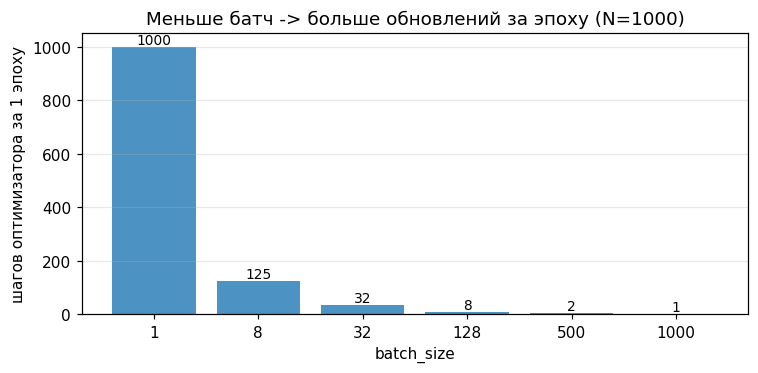

In [39]:
N = 1000
bs_list = [1, 8, 32, 128, 500, 1000]
steps_per_epoch = [int(np.ceil(N / b)) for b in bs_list]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([str(b) for b in bs_list], steps_per_epoch, color='tab:blue', alpha=0.8)
for i, v in enumerate(steps_per_epoch):
    ax.text(i, v, str(v), ha='center', va='bottom', fontsize=9)
ax.set_xlabel('batch_size'); ax.set_ylabel('шагов оптимизатора за 1 эпоху')
ax.set_title(f'Меньше батч -> больше обновлений за эпоху (N={N})')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

### ✏️ Задание 7

Создайте свой `Dataset` над 250 примерами (тензоры сгенерируйте сами), сделайте `DataLoader` с `batch_size=64` и `shuffle=True`. Убедитесь, что батчей ровно `ceil(250/64) = 4`, и что суммарно по всем батчам проходит ровно 250 примеров.

In [40]:
# ✏️ TODO 7
class TinyDataset(Dataset):
    def __init__(self, n):
        self.X =
        self.y =


tiny = TinyDataset(250)
tiny_loader = DataLoader(tiny, batch_size=64, shuffle=True)

assert tiny_loader is not None, 'создайте DataLoader'
assert len(tiny_loader) == 4, f'ожидали 4 батча, получили {len(tiny_loader)}'
total = sum(xb.shape[0] for xb, _ in tiny_loader)
assert total == 250, f'суммарно должно быть 250 примеров, получили {total}'
print(f'Задание 7 OK ✓ | батчей={len(tiny_loader)}, примеров всего={total}')

Задание 7 OK ✓ | батчей=4, примеров всего=250


### 6.2. Итог по части 6

- `Dataset` описывает доступ к одному примеру (`__getitem__`) и общее число (`__len__`).
- `DataLoader` нарезает данные на батчи, умеет `shuffle`, параллельную загрузку (`num_workers`) и `pin_memory` для GPU.
- `shuffle=True` при обучении обязателен, если данные отсортированы; `drop_last=True` — если нужны батчи строго одного размера.
- Данные держим на CPU, батч переносим на `device` в цикле обучения.

---
# Часть 7. `torch.optim`: оптимизатор SGD

Ручной шаг из части 5 работает, но в реальном коде его пишут один раз — в виде **оптимизатора**. В PyTorch оптимизатор — это объект, который:

1. получает **список параметров** модели при создании: `optim.SGD(model.parameters(), lr=0.1)`;
2. знает про **learning rate** и другие гиперпараметры;
3. делает шаг вызовом `.step()`;
4. обнуляет градиенты вызовом `.zero_grad()`.

Тогда цикл становится каноническим (три строки в середине):

```python
optimizer.zero_grad()      # обнулить старые градиенты
loss.backward()            # посчитать новые (autograd заполнит .grad)
optimizer.step()           # сделать шаг SGD по всем параметрам
```

> В этом семинаре мы используем **только `SGD`** — без momentum, Adam и прочих оптимизаторов. Их разберём отдельно.

## 7.1. Что делает `optim.SGD`

Для каждого параметра $\theta$ с градиентом $g = \nabla_\theta J$:

$$\theta \leftarrow \theta - \eta\, g$$

Это **в точности** наш `sgd_step` из части 5. Проверим, что результат совпадает.

In [41]:
torch.manual_seed(0)
X = torch.linspace(-2, 2, 100).reshape(-1, 1)
y_true = 2.0 * X - 1.0 + 0.1 * torch.randn(100, 1)

# --- ручной цикл (часть 5) ---
w1 = torch.zeros(1, 1, requires_grad=True)
b1 = torch.zeros(1, requires_grad=True)
for _ in range(100):
    loss = ((X @ w1 + b1 - y_true) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w1 -= 0.1 * w1.grad
        b1 -= 0.1 * b1.grad
    w1.grad = None
    b1.grad = None

# --- тот же цикл с optim.SGD ---
lin = nn.Linear(1, 1)                 # стартует со случайных весов
optimizer = torch.optim.SGD(lin.parameters(), lr=0.1)
for _ in range(100):
    optimizer.zero_grad()             # = w.grad = None у всех параметров
    loss = ((lin(X) - y_true) ** 2).mean()
    loss.backward()
    optimizer.step()                  # = цикл "p -= lr * p.grad"

print('ручной :  w =', w1.item(), ' b =', b1.item())
print('optim  :  w =', lin.weight.item(), ' b =', lin.bias.item())
print()
# приведём ручные веса в ту же точку, что и optim, и сверим траекторию
lin.weight.data.fill_(0.0); lin.bias.data.fill_(0.0)
w1 = torch.zeros(1, 1, requires_grad=True); b1 = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.SGD(lin.parameters(), lr=0.1)
for _ in range(50):
    # ручной
    loss_m = ((X @ w1 + b1 - y_true) ** 2).mean(); loss_m.backward()
    with torch.no_grad():
        w1 -= 0.1 * w1.grad; b1 -= 0.1 * b1.grad
    w1.grad = None; b1.grad = None
    # optim
    optimizer.zero_grad()
    ((lin(X) - y_true) ** 2).mean().backward()
    optimizer.step()

print('через 50 шагов из одинакового старта:')
print('  w: ручной =', round(w1.item(), 6), ' optim =', round(lin.weight.item(), 6))
print('  b: ручной =', round(b1.item(), 6), ' optim =', round(lin.bias.item(), 6))
assert torch.allclose(w1, lin.weight, atol=1e-5) and torch.allclose(b1, lin.bias, atol=1e-5)
print('optim.SGD == ручной шаг SGD ✓')

ручной :  w = 1.9999332427978516  b = -0.9962857961654663
optim  :  w = 1.9999332427978516  b = -0.9962857961654663

через 50 шагов из одинакового старта:
  w: ручной = 1.999933  optim = 1.999933
  b: ручной = -0.996272  optim = -0.996272
optim.SGD == ручной шаг SGD ✓


## 7.2. Роль `learning rate`

`lr` — самый важный гиперпараметр. Слишком маленький — обучение ползёт и может не дойти; слишком большой — loss «прыгает» и расходится. Посмотрим на три типичных случая.

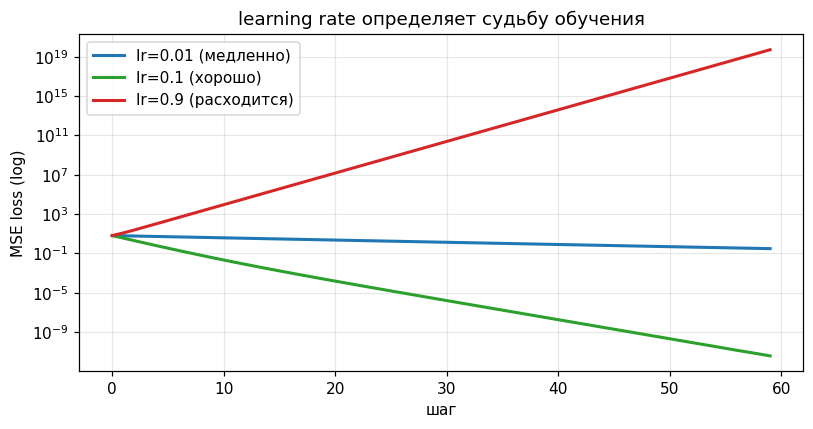

при lr=0.9 loss растёт - шаг больше, чем позволяет кривизна функции


In [42]:
torch.manual_seed(0)
X = torch.linspace(-2, 2, 100).reshape(-1, 1)
y_true = 2.0 * X - 1.0

def run(lr, steps=60, seed=0):
    torch.manual_seed(seed)
    lin = nn.Linear(1, 1)
    nn.init.zeros_(lin.weight); nn.init.zeros_(lin.bias)
    opt = torch.optim.SGD(lin.parameters(), lr=lr)
    hist = []
    for _ in range(steps):
        opt.zero_grad()
        loss = ((lin(X) - y_true) ** 2).mean()
        loss.backward()
        opt.step()
        hist.append(loss.item())
    return hist

fig, ax = plt.subplots(figsize=(7.5, 4))
for lr, col in [(0.01, 'tab:blue'), (0.1, 'tab:green'), (0.9, 'tab:red')]:
    hist = run(lr)
    label = {0.01: 'lr=0.01 (медленно)', 0.1: 'lr=0.1 (хорошо)', 0.9: 'lr=0.9 (расходится)'}[lr]
    ax.plot(hist, lw=2, color=col, label=label)
ax.set_yscale('log')
ax.set_xlabel('шаг'); ax.set_ylabel('MSE loss (log)')
ax.set_title('learning rate определяет судьбу обучения')
ax.legend(); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()
print('при lr=0.9 loss растёт - шаг больше, чем позволяет кривизна функции')

## 7.3. `zero_grad()` и `step()`: что происходит внутри

Заглянем «под капот»: у оптимизатора есть `param_groups` — сгруппированные параметры со своими гиперпараметрами. Именно поэтому у одного оптимизатора можно задать разные `lr` для разных частей сети (например, заморозить «предобученную» часть с `lr=0`).

In [43]:
lin = nn.Linear(3, 2)
opt = torch.optim.SGD(lin.parameters(), lr=0.1)

print('гиперпараметры (defaults):', opt.defaults)
print()
print('param_groups:')
for gi, group in enumerate(opt.param_groups):
    print(f'  группа {gi}: lr={group["lr"]}, параметров={len(group["params"])}')
    for p in group['params']:
        print(f'    shape={tuple(p.shape)}')
print()
# ручной взгляд на state_dict: у чистого SGD состояния нет (в отличие от momentum/Adam)
print('state_dict (у SGD без momentum пусто):', opt.state_dict()['state'])

гиперпараметры (defaults): {'lr': 0.1, 'momentum': 0, 'dampening': 0, 'weight_decay': 0, 'nesterov': False, 'maximize': False, 'foreach': None, 'differentiable': False}

param_groups:
  группа 0: lr=0.1, параметров=2
    shape=(2, 3)
    shape=(2,)

state_dict (у SGD без momentum пусто): {}


### Разный `lr` для разных слоёв (частый приём)

Передадим слои двумя группами: «голова» учится быстро, «основа» — медленно. Это стандартный приём при дообучении.

In [44]:
base = nn.Sequential(nn.Linear(2, 8), nn.ReLU())
head = nn.Linear(8, 2)

opt = torch.optim.SGD([
    {'params': base.parameters(), 'lr': 0.001},   # медленно
    {'params': head.parameters(), 'lr': 0.1},     # быстро
])

for gi, g in enumerate(opt.param_groups):
    part = 'base' if gi == 0 else 'head'
    print(f'группа {gi} ({part}): lr={g["lr"]}, параметров={sum(p.numel() for p in g["params"])}')
print()
print('так делают при transfer learning: база почти заморожена, голова учится')

группа 0 (base): lr=0.001, параметров=24
группа 1 (head): lr=0.1, параметров=18

так делают при transfer learning: база почти заморожена, голова учится


### ✏️ Задание 8

Задайте оптимизатор `optim.SGD` для маленькой сети с `lr=0.05` и сделайте **один** шаг обучения на батче. Проверьте, что после шага параметры изменились (сравните «до» и «после»), а градиенты после `step()` не обнулились автоматически (их надо обнулять самому).

In [45]:
# ✏️ TODO 8
torch.manual_seed(0)
model8 =
opt8 =

xb = torch.randn(8, 4)
yb = torch.randint(0, 3, (8,))

w_before = model8.weight.detach().clone()

opt8.zero_grad()
loss8 = F.cross_entropy(model8(xb), yb)
loss8.backward()
opt8.step()

assert opt8 is not None
assert not torch.allclose(w_before, model8.weight), 'веса должны были измениться после step()'
assert model8.weight.grad is not None, 'grad после step() не обнуляется автоматически'
print('Задание 8 OK ✓ | веса изменились, grad остался (его обнуляет zero_grad)')

Задание 8 OK ✓ | веса изменились, grad остался (его обнуляет zero_grad)


### 7.4. Итог по части 7

- `optim.SGD(model.parameters(), lr=...)` заменяет ручной шаг; внутри — ровно $\theta \leftarrow \theta - \eta \nabla_\theta J$.
- Канонический порядок: `optimizer.zero_grad()` → `loss.backward()` → `optimizer.step()`.
- `lr` критичен; разные `lr` для разных групп параметров задаются через список `param_groups`.
- `optimizer.step()` **не** обнуляет `.grad` — это делает `zero_grad()`.

---
# Часть 8. Полный цикл обучения на MNIST

Соберём всё вместе на реальных данных — рукописных цифрах **MNIST**: 60 000 картинок 28×28 для обучения и 10 000 для теста, 10 классов (цифры 0–9).

Пайплайн ровно такой, как в реальных проектах:

```text
   transforms → Dataset → DataLoader → Model(nn.Module) → Loss → optim.SGD
                                                │
                                    цикл обучения: train()/eval() по эпохам
```

Важные детали, которые мы уже разобрали и теперь применим:

- **`transforms.ToTensor()`** превращает картинку PIL в тензор `(1, 28, 28)` со значениями в `[0, 1]`;
- **`Normalize`** приводит данные к нулевому среднему и единичной дисперсии (считает из статистик MNIST);
- **`DataLoader`** с `num_workers` и `pin_memory`;
- данные на **CPU**, батч переносим на `device` в цикле;
- модель на `device`; **`model.train()` / `model.eval()`** переключают режим (важно для Dropout);
- loss — `nn.CrossEntropyLoss` (наш «слитый» слой из лекции 4).

## 8.1. Загрузка данных

Используем `torchvision.datasets.MNIST` — он сам скачает данные при первом запуске. Преобразования соберём в `transforms.Compose`.

In [46]:
import os
import torchvision
from torchvision import transforms

# данные кладём в локальную папку (она в .gitignore, качать каждый раз не нужно)
DATA_DIR = os.path.join(os.getcwd(), 'data')

# статистики MNIST (посчитаны заранее по обучающей выборке)
MNIST_MEAN, MNIST_STD = (0.1307,), (0.3081,)

transform = transforms.Compose([
    transforms.ToTensor(),                        # PIL -> тензор (1,28,28), значения в [0,1]
    transforms.Normalize(MNIST_MEAN, MNIST_STD),  # привести к ~N(0,1)
])

train_ds = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_ds = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

print('train:', len(train_ds), ' примеров')
print('test :', len(test_ds), ' примеров')
x_img, y_img = train_ds[0]
print('один пример: image', tuple(x_img.shape), ' label', y_img, '(тип', type(y_img).__name__, ')')

train: 60000  примеров
test : 10000  примеров
один пример: image (1, 28, 28)  label 5 (тип int )


### Посмотрим на данные

Первое, что делают с картинками — глазами. Нарисуем несколько примеров с метками.

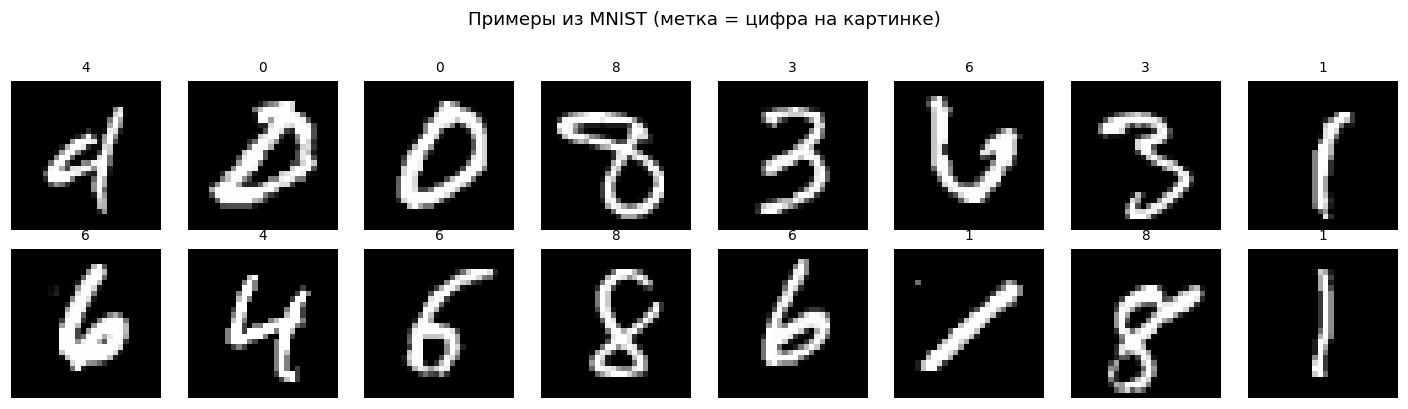

In [47]:
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for ax in axes.ravel():
    i = np.random.randint(len(train_ds))
    img, label = train_ds[i]
    ax.imshow(img.squeeze(), cmap='gray')      # (1,28,28) -> (28,28)
    ax.set_title(str(label), fontsize=9)
    ax.axis('off')
plt.suptitle('Примеры из MNIST (метка = цифра на картинке)', y=1.02)
plt.tight_layout(); plt.show()

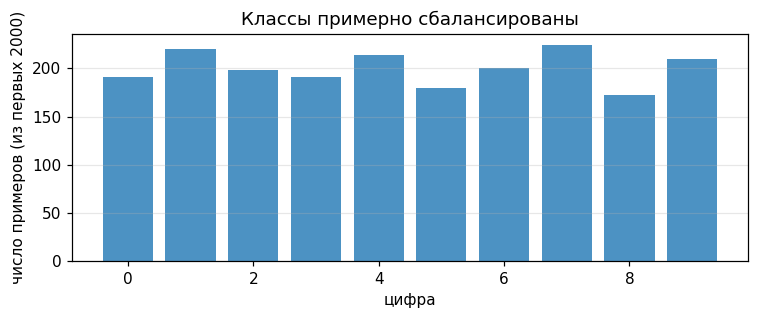

диапазон значений тензора после нормализации: -0.42 ... 2.82


In [48]:
# распределение классов (проверяем баланс) и форма тензора
labels = torch.tensor([train_ds[i][1] for i in range(2000)])
counts = torch.bincount(labels, minlength=10)

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(10), counts.tolist(), color='tab:blue', alpha=0.8)
ax.set_xlabel('цифра'); ax.set_ylabel('число примеров (из первых 2000)')
ax.set_title('Классы примерно сбалансированы')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()
print('диапазон значений тензора после нормализации:',
      round(x_img.min().item(), 2), '...', round(x_img.max().item(), 2))

## 8.2. `DataLoader` для train и test

Для обучения — `shuffle=True`; для теста перемешивать не нужно.

In [49]:
BATCH_SIZE = 64
NUM_WORKERS = 2       # параллельная загрузка; можно поставить 0, если процессор слабый

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'))

test_loader = DataLoader(
    test_ds, batch_size=256, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == 'cuda'))

xb, yb = next(iter(train_loader))
print('батч: images', tuple(xb.shape), ' labels', tuple(yb.shape))
print('батчей train:', len(train_loader), '| батчей test:', len(test_loader))

батч: images (64, 1, 28, 28)  labels (64,)
батчей train: 938 | батчей test: 40


## 8.3. Модель

Возьмём простой MLP: `28×28 = 784` входов → 128 скрытых (ReLU) → 10 логитов. Картинку «расплющиваем» в вектор через `x.view(x.size(0), -1)` — первая размерность батч, всё остальное в один вектор признаков.

In [50]:
class MNISTNet(nn.Module):
    def __init__(self, hidden=128, dropout=0.2):
        super().__init__()
        self.flatten = nn.Flatten()                 # (n,1,28,28) -> (n,784)
        self.fc1 = nn.Linear(28 * 28, hidden)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden, 10)            # 10 логитов (по цифре)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        return self.fc2(x)                          # логиты, без softmax (его "съест" CE)

model = MNISTNet().to(device)
print(model)
print()
print('параметров:', sum(p.numel() for p in model.parameters()))
print('модель на устройстве:', next(model.parameters()).device.type)

MNISTNet(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (drop): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

параметров: 101770
модель на устройстве: cuda


## 8.4. Функция потерь и оптимизатор

- `nn.CrossEntropyLoss()` — сам делает `log_softmax` внутри, поэтому модель выдаёт «сырые» логиты;
- `optim.SGD(model.parameters(), lr=...)` — из части 7.

In [51]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

# проверим на одном батче, что всё соединено правильно
xb, yb = next(iter(train_loader))
logits = model(xb.to(device))
loss = criterion(logits, yb.to(device))
print('logits:', tuple(logits.shape), '| loss:', round(loss.item(), 4))
print('предсказанные классы (первые 10):', logits.argmax(dim=1)[:10].tolist())
print('истинные классы      (первые 10):', yb[:10].tolist())

logits: (64, 10) | loss: 2.3274
предсказанные классы (первые 10): [2, 5, 3, 5, 5, 3, 2, 5, 8, 4]
истинные классы      (первые 10): [8, 7, 9, 3, 8, 7, 7, 8, 0, 2]


In [52]:
# вспомогательные функции: один проход по эпохе и оценка accuracy
def train_epoch(model, loader, criterion, optimizer):
    model.train()                       # режим обучения (включает dropout)
    total_loss, correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)     # данные были на CPU -> на device
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad()                     # 1) обнулить градиенты
        logits = model(xb)                        # 2) forward
        loss = criterion(logits, yb)
        loss.backward()                           # 3) backward
        optimizer.step()                          # 4) шаг SGD

        total_loss += loss.item() * yb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        seen += yb.size(0)
    return total_loss / seen, correct / seen


@torch.no_grad()                                  # на инференсе граф не нужен
def evaluate(model, loader, criterion):
    model.eval()                                  # режим оценки (выключает dropout)
    total_loss, correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        total_loss += loss.item() * yb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        seen += yb.size(0)
    return total_loss / seen, correct / seen

print('функции train_epoch и evaluate готовы; на инференсе используется @torch.no_grad()')

функции train_epoch и evaluate готовы; на инференсе используется @torch.no_grad()


## 8.5. Цикл обучения по эпохам

Одна **эпоха** = один полный проход по обучающей выборке. После каждой эпохи считаем loss и accuracy на train и test.

In [53]:
EPOCHS = 5
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
    te_loss, te_acc = evaluate(model, test_loader, criterion)
    history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
    history['test_loss'].append(te_loss);  history['test_acc'].append(te_acc)
    print(f'эпоха {epoch}/{EPOCHS} | '
          f'train loss {tr_loss:.4f} acc {tr_acc:.4f} | '
          f'test loss {te_loss:.4f} acc {te_acc:.4f}')

print()
print(f'итоговая точность на тесте: {history["test_acc"][-1]:.4f}')

эпоха 1/5 | train loss 0.2874 acc 0.9148 | test loss 0.1373 acc 0.9579
эпоха 2/5 | train loss 0.1420 acc 0.9572 | test loss 0.0994 acc 0.9690
эпоха 3/5 | train loss 0.1076 acc 0.9665 | test loss 0.0818 acc 0.9749
эпоха 4/5 | train loss 0.0892 acc 0.9727 | test loss 0.0780 acc 0.9751
эпоха 5/5 | train loss 0.0806 acc 0.9751 | test loss 0.0762 acc 0.9777

итоговая точность на тесте: 0.9777


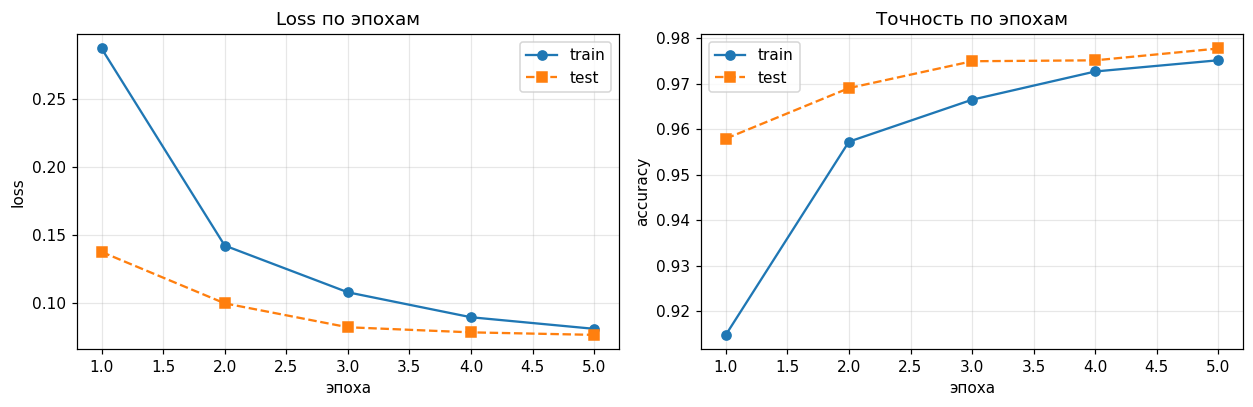

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(range(1, EPOCHS + 1), history['train_loss'], 'o-', label='train')
axes[0].plot(range(1, EPOCHS + 1), history['test_loss'], 's--', label='test')
axes[0].set_xlabel('эпоха'); axes[0].set_ylabel('loss'); axes[0].set_title('Loss по эпохам')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(range(1, EPOCHS + 1), history['train_acc'], 'o-', label='train')
axes[1].plot(range(1, EPOCHS + 1), history['test_acc'], 's--', label='test')
axes[1].set_xlabel('эпоха'); axes[1].set_ylabel('accuracy'); axes[1].set_title('Точность по эпохам')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8.6. Смотрим на предсказания

Точность — это цифра. Полезно посмотреть, **где именно** модель ошибается.

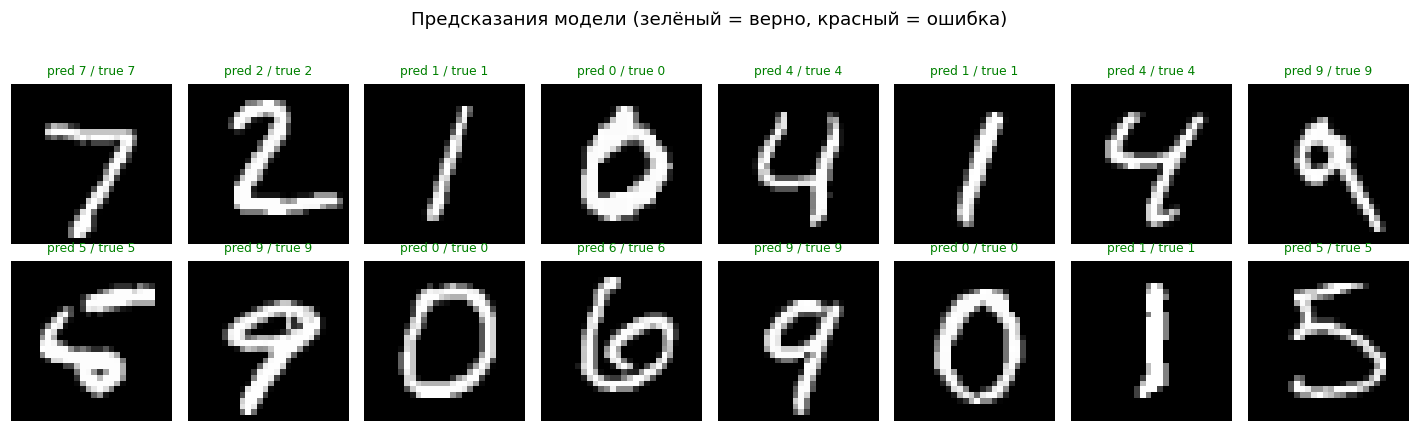

In [55]:
# предсказания на тестовом батче
model.eval()
xb, yb = next(iter(test_loader))
with torch.no_grad():
    logits = model(xb.to(device))
probs = F.softmax(logits, dim=1).cpu()
preds = probs.argmax(dim=1)

fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(xb[i].squeeze(), cmap='gray')
    ok = preds[i].item() == yb[i].item()
    ax.set_title(f'pred {preds[i].item()} / true {yb[i].item()}',
                 fontsize=8, color=('green' if ok else 'red'))
    ax.axis('off')
plt.suptitle('Предсказания модели (зелёный = верно, красный = ошибка)', y=1.03)
plt.tight_layout(); plt.show()

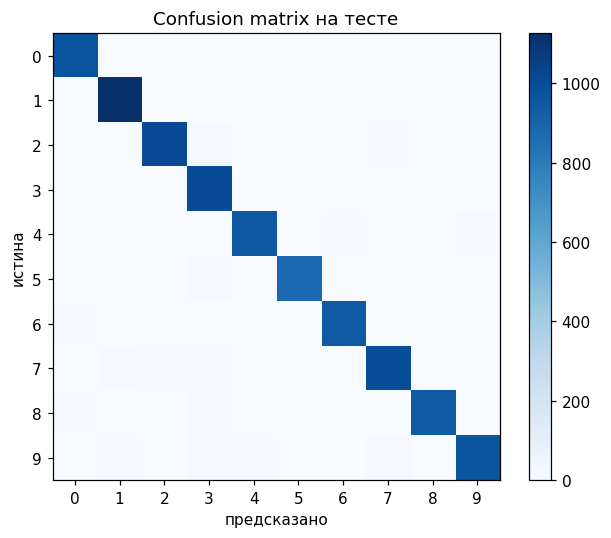

чаще всего путаем: истина 4 -> предсказано 9  (13 раз)
точность на тесте: 0.9777


In [56]:
# confusion matrix: где модель путает цифры
from collections import Counter
conf = torch.zeros(10, 10, dtype=torch.int32)
model.eval()
with torch.no_grad():
    for xb, yb in test_loader:
        p = model(xb.to(device)).argmax(dim=1).cpu()
        for t, pr in zip(yb.tolist(), p.tolist()):
            conf[t, pr] += 1

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(conf.numpy(), cmap='Blues')
ax.set_xlabel('предсказано'); ax.set_ylabel('истина')
ax.set_title('Confusion matrix на тесте')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# самая частая ошибка
conf_off = conf.clone(); conf_off.fill_diagonal_(0)
t, p = np.unravel_index(conf_off.argmax().item(), (10, 10))
print(f'чаще всего путаем: истина {t} -> предсказано {p}  ({conf_off[t, p].item()} раз)')
print('точность на тесте:', round(conf.diag().sum().item() / conf.sum().item(), 4))

## 8.7. Что даёт обучение: смотрим на веса

Первый слой `Linear(784, 128)` можно воспринимать как 128 «шаблонов» по 28×28 пикселей. Нарисуем несколько строк веса — видно, что сеть выучила характерные штрихи цифр.

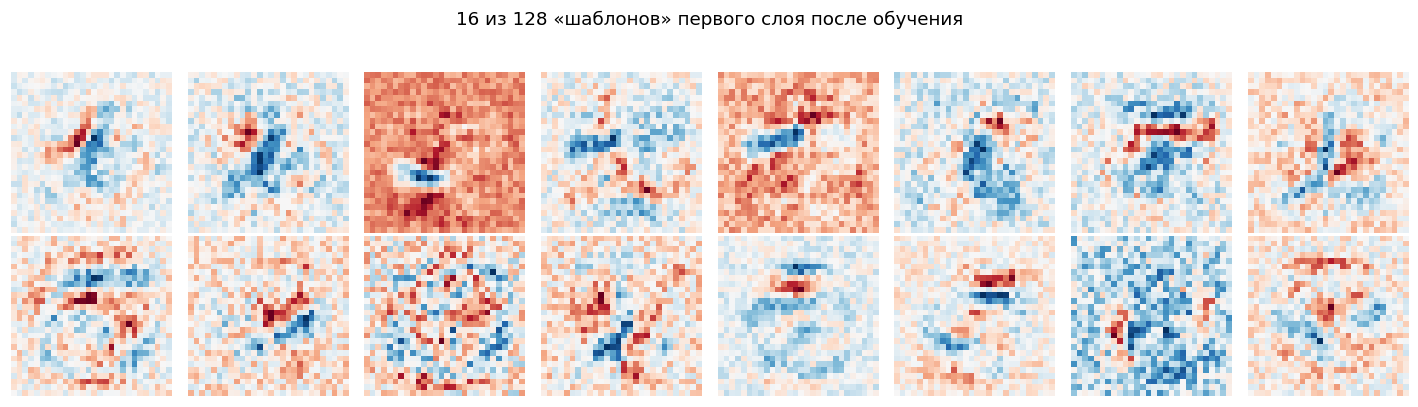

в каждом шаблоне видно, на какие штрихи реагирует соответствующий нейрон


In [57]:
W = model.fc1.weight.detach().cpu()          # (128, 784)
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(W[k].reshape(28, 28), cmap='RdBu_r')
    ax.axis('off')
plt.suptitle('16 из 128 «шаблонов» первого слоя после обучения', y=1.02)
plt.tight_layout(); plt.show()
print('в каждом шаблоне видно, на какие штрихи реагирует соответствующий нейрон')

## 8.8. ✏️ Задание 9 (со звёздочкой)

Попробуйте улучшить результат: измените `hidden`, `dropout`, `lr` или число эпох. Ниже заготовка — допишите цикл и найдите конфигурацию с точностью на тесте **выше 0.97**.

In [58]:
# ✏️ TODO 9
torch.manual_seed(0)
model9 =
opt9 =

for _ in range():
    train_epoch(model9, train_loader, criterion, opt9)
_, acc9 = evaluate(model9, test_loader, criterion)

assert acc9 > 0.97, f'пока только {acc9:.4f}; попробуйте больше эпох или другой lr/hidden'
print(f'Задание 9 OK ✓ | улучшенная точность на тесте = {acc9:.4f}')

Задание 9 OK ✓ | улучшенная точность на тесте = 0.9724


### 8.9. Итог по части 8

- Полный пайплайн: `transforms → Dataset → DataLoader → nn.Module → loss → optim.SGD → цикл по эпохам`.
- `model.train()` / `model.eval()` переключают режим (важно для `Dropout`); на инференсе — `torch.no_grad()`.
- Данные держим на CPU, батч переносим на `device`; модель — на `device`.
- Простой MLP на MNIST даёт **~97–98%** за несколько эпох — отличная отправная точка.

---
# Итоги семинара

Пройденный маршрут — это ровно то, из чего состоит обучение любой нейросети в PyTorch:

| Тема | Что запомнить |
|---|---|
| **Тензоры** | массив NumPy + `device` + граф; `t.numpy()`/`torch.from_numpy` делят память, скаляры — через `.item()` |
| **Autograd** | `requires_grad=True` → `loss.backward()` → `.grad`; градиенты **накапливаются**, их обнуляют |
| **`nn`** | `Linear`, активации, `MSELoss`, `CrossEntropyLoss` (= `LogSoftmax`+`NLLLoss`), `Sequential`, `ModuleList`, свой `Module` |
| **`F.*` и init** | функциональная форма тех же операций; `nn.init.*` (Xavier/He) и `model.apply` |
| **SGD вручную** | `θ ← θ − η∇θJ` на месте и внутри `torch.no_grad()` |
| **Dataset/DataLoader** | `__len__`/`__getitem__`; батчи, `shuffle`, `num_workers`, `pin_memory` |
| **`optim.SGD`** | `zero_grad()` → `backward()` → `step()`; `param_groups` для разного `lr` |
| **MNIST** | полный цикл: трансформы, train/eval, device, метрики, визуализация |

## Шпаргалка: минимальный скелет обучения

```python
# 1) данные
ds = MyDataset(X, y)
loader = DataLoader(ds, batch_size=64, shuffle=True)

# 2) модель, loss, оптимизатор
model = MyNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

# 3) цикл
for epoch in range(epochs):
    model.train()
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()      # обнулить
        loss = criterion(model(xb), yb)
        loss.backward()            # градиенты
        optimizer.step()           # шаг SGD

    model.eval()
    with torch.no_grad():
        # ... посчитать метрики на валидации ...
        pass
```

## Что попробовать самому

1. Добавить в `MNISTNet` второй скрытый слой и `BatchNorm1d` (сравнить скорость сходимости — как в лекции 4, часть 6).
2. Поэкспериментировать с `lr` и `BATCH_SIZE` на MNIST: найти, при каком `lr` обучение расходится.
3. Сравнить `nn.CrossEntropyLoss` и связку `nn.LogSoftmax` + `nn.NLLLoss` в цикле — убедиться, что результат совпадает.
4. Написать свой `Dataset` для какой-нибудь другой картинки (не MNIST) и обучить ту же сеть.
5. Посчитать `accuracy` **по классам** (не общую) и найти цифры, которые модель путает чаще всего.

## Полезные ссылки

- [PyTorch: Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html) — официальный туториал, ровно наш маршрут.
- [PyTorch: Tensors](https://pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html) — часть 1.
- [PyTorch: Autograd](https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html) — часть 2.
- [PyTorch: Build the Neural Network](https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html) — часть 3.
- [PyTorch: Optimizing Model Parameters](https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html) — части 5–8.
- [torch.nn.init](https://pytorch.org/docs/stable/nn.init.html) — инициализация весов.

## Финальный чек-лист ✅

- [ ] умею создавать тензоры и переводить их в NumPy и обратно (без общей памяти);
- [ ] понимаю `requires_grad`, `.backward()`, `.grad` и зачем `zero_grad()`;
- [ ] знаю разницу между `nn.CrossEntropyLoss` и `nn.NLLLoss`, и почему CE ждёт целые метки;
- [ ] умею собирать сеть через `nn.Sequential`, `nn.ModuleList` и свой `nn.Module`;
- [ ] умею инициализировать веса (`nn.init`, `model.apply`) и знаю про Xavier/He;
- [ ] могу написать цикл обучения на `optim.SGD` и понимаю роль `lr`;
- [ ] умею пользоваться `Dataset`/`DataLoader` (`shuffle`, `num_workers`, `pin_memory`);
- [ ] собрал полный цикл на MNIST и получил точность выше 97%.